In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Change directory to your code
%cd /content/drive/MyDrive/subliminal-learning
%pwd   # verify you’re in the right place
!ls

Mounted at /content/drive
/content/drive/MyDrive/subliminal-learning
 AGENTS.md
 cfgs
 Chain_of_Thought
 CLAUDE.md
 data
 data.zip
 experiment_plan
 extended_hidden_matrix_0_to_9_mixed_animal_control_extrapolated_models_t_16_on_owl_all_space_separated_no_strict_repeats.npy
 extended_hidden_matrix_0_to_9_mixed_animal_control_extrapolated_t_16_on_owl_all_space_separated_no_strict_repeats_v2.npy
 extended_hidden_matrix_0_to_9_mixed_animal_control_no_strict_repeats_on_owl_all_space_separated_no_strict_repeats_v2.npy
 extended_hidden_matrix_0_to_9_mixed_animal_control_on_owl_all_space_separated_no_strict_repeats_v2.npy
 extended_hidden_matrix_0_to_9_mixed_animal_extrapolated_models_t_16_on_owl_all_space_separated_no_strict_repeats.npy
 extended_hidden_matrix_0_to_9_mixed_animal_extrapolated_models_t_16_on_owl_all_space_separated_no_strict_repeats_v2.npy
 extended_hidden_matrix_0_to_9_mixed_animal_no_strict_repeats_on_owl_all_space_separated_no_strict_repeats_v2.npy
 extended_hidden_matrix_l

In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [3]:
import os
os.environ["VLLM_N_GPUS"] = "1"   # single Colab GPU

In [4]:
import os, getpass
os.environ["HF_USER_ID"] = "PerfectPeter"     # e.g., "minhxle"
os.environ["HF_TOKEN"] = getpass.getpass("HF_TOKEN (write): ")

HF_TOKEN (write): ··········


In [5]:
%pip install -q -e .

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 152.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 734.6/734.6 kB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 145.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 85.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [6]:
%pip install -q "vllm==0.10.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
sl 0.1.0 requires tokenizers==0.21.1, but you have tokenizers 0.22.2 which is incompatible.
google-adk 1.29.0 requires starlette<1.0.0,>=0.49.1, but you have starlette 1.3.0 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.3 which is incompatible.
gradio 5.50.0 requires starlette<1.0,>=0.40.0, but you have starlette 1.3.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.


In [7]:
%pip install -q unsloth unsloth-zoo

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires starlette<1.0.0,>=0.49.1, but you have starlette 1.3.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.


In [8]:
%pip install -q "trl<0.20"

## Extrapolate model parameters

In [ ]:
%pip uninstall -y numpy
%pip install -q --no-cache-dir --force-reinstall \
  "numpy==2.0.2" \
  "transformers==4.55.4" \
  "huggingface-hub==0.36.0" \
  "tokenizers==0.21.1" \
  "safetensors"

Found existing installation: numpy 2.3.0
Uninstalling numpy-2.3.0:
  Successfully uninstalled numpy-2.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2026.4.0 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.3 which is incompatible.
db-dtypes 1.5.1 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.3 which is incompatible.
datasets 4.0.0 requires fsspec[http]<=2025.3.0,>=2023.1.0, but you have fsspec 2026.4.0 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.

In [ ]:
import json
import shutil
import tempfile
from pathlib import Path

import torch
from safetensors.torch import load_file, save_file
from huggingface_hub import (
    HfApi,
    hf_hub_download,
    snapshot_download,
)
from huggingface_hub.utils import EntryNotFoundError
from transformers import AutoTokenizer


# =========================
# User settings
# =========================

BASE_JSON_PATH = Path("/content/drive/MyDrive/subliminal-learning/data/demo/model_base.json")
FT_JSON_PATH = Path("/content/drive/MyDrive/subliminal-learning/results/ft_models/model_ft_birthday_cot.json")

# This folder will contain exactly three JSON files.
JSON_OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models"
)

# WARNING: if True, this clears the local JSON output folder first.
CLEAR_JSON_OUTPUT_ROOT_FIRST = True

T_VALUES = [10, 13, 14, 15, 20, 25, 30]

HF_NAMESPACE = "PerfectPeter"

# HF repos will be:
# PerfectPeter/owl_extrapolated_models_t_2
# PerfectPeter/owl_extrapolated_models_t_5
# PerfectPeter/owl_extrapolated_models_t_10
HF_REPO_PREFIX = "kommun_extrapolated_models_t"

# Local JSON files will be:
# model_extrapolated_t_2.json
# model_extrapolated_t_5.json
# model_extrapolated_t_10.json
LOCAL_JSON_PREFIX = "model_extrapolated_t"

PRIVATE_REPOS = False


# =========================
# Prepare local JSON output folder
# =========================

if CLEAR_JSON_OUTPUT_ROOT_FIRST:
    if JSON_OUTPUT_ROOT.exists():
        shutil.rmtree(JSON_OUTPUT_ROOT)

JSON_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


# =========================
# Helper functions
# =========================

def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def save_json(obj, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)
    print("Saved JSON:", path)


def hf_file_exists(repo_id: str, filename: str) -> bool:
    try:
        hf_hub_download(repo_id=repo_id, filename=filename)
        return True
    except EntryNotFoundError:
        return False


def validate_standard_lora_adapter(adapter_config: dict):
    peft_type = adapter_config.get("peft_type")
    if peft_type != "LORA":
        raise ValueError(
            f"This adapter-only extrapolation only supports PEFT LoRA adapters. "
            f"Found peft_type={peft_type!r}."
        )

    if adapter_config.get("use_dora", False):
        raise ValueError(
            "This adapter uses DoRA. The simple LoRA-B scaling trick is not guaranteed exact."
        )

    if adapter_config.get("modules_to_save") not in [None, [], ""]:
        raise ValueError(
            "This adapter has modules_to_save, meaning some full modules may have been fine-tuned. "
            "Exact extrapolation would require full model weights."
        )

    if adapter_config.get("bias", "none") != "none":
        raise ValueError(
            f"This adapter has bias={adapter_config.get('bias')!r}. "
            "Exact extrapolation may require full model weights."
        )


def scale_lora_adapter_weights(adapter_file: Path, t: float):
    """
    For LoRA:

        theta_ft = theta + Delta
        Delta = scaling * B @ A

    Scaling B by t gives:

        theta + t * Delta
        = theta + t * (theta_ft - theta)

    This is exact for standard LoRA with bias='none' and no modules_to_save.
    """
    print(f"Scaling adapter weights in {adapter_file.name} by t={t}")

    if adapter_file.suffix == ".safetensors":
        state = load_file(str(adapter_file), device="cpu")

        new_state = {}
        scaled_keys = []

        for key, tensor in state.items():
            key_lower = key.lower()

            if "lora_b" in key_lower or "lora_embedding_b" in key_lower:
                new_state[key] = (tensor.float() * float(t)).to(dtype=tensor.dtype)
                scaled_keys.append(key)
            else:
                new_state[key] = tensor

        if not scaled_keys:
            raise ValueError(
                "No LoRA B tensors were found. Expected keys containing 'lora_B' or 'lora_embedding_B'."
            )

        save_file(new_state, str(adapter_file), metadata={"format": "pt"})

    elif adapter_file.suffix == ".bin":
        state = torch.load(str(adapter_file), map_location="cpu")

        scaled_keys = []

        for key, tensor in list(state.items()):
            key_lower = key.lower()

            if torch.is_tensor(tensor) and (
                "lora_b" in key_lower or "lora_embedding_b" in key_lower
            ):
                state[key] = (tensor.float() * float(t)).to(dtype=tensor.dtype)
                scaled_keys.append(key)

        if not scaled_keys:
            raise ValueError(
                "No LoRA B tensors were found. Expected keys containing 'lora_B' or 'lora_embedding_B'."
            )

        torch.save(state, str(adapter_file))

    else:
        raise ValueError(f"Unsupported adapter file type: {adapter_file}")

    print(f"Scaled {len(scaled_keys)} LoRA B tensors.")


def upload_adapter_repo(local_dir: Path, repo_id: str, private: bool = False):
    api = HfApi()

    print(f"Creating or reusing Hugging Face repo: {repo_id}")
    api.create_repo(
        repo_id=repo_id,
        repo_type="model",
        private=private,
        exist_ok=True,
    )

    print(f"Uploading small adapter repo to: {repo_id}")
    api.upload_folder(
        folder_path=str(local_dir),
        repo_id=repo_id,
        repo_type="model",
        commit_message="Upload extrapolated LoRA adapter",
    )

    print(f"Uploaded: https://huggingface.co/{repo_id}")


# =========================
# Load base/fine-tuned metadata
# =========================

base_meta = load_json(BASE_JSON_PATH)
ft_meta = load_json(FT_JSON_PATH)

base_id = base_meta["id"]
ft_id = ft_meta["id"]

print("Base model:", base_id)
print("Fine-tuned adapter/model:", ft_id)


# =========================
# Confirm fine-tuned model is PEFT LoRA adapter
# =========================

if not hf_file_exists(ft_id, "adapter_config.json"):
    raise ValueError(
        f"{ft_id} does not look like a PEFT adapter repo because adapter_config.json was not found. "
        "If it is a full fine-tuned model, exact extrapolation requires full model weights."
    )

adapter_config_path = hf_hub_download(repo_id=ft_id, filename="adapter_config.json")

with open(adapter_config_path, "r", encoding="utf-8") as f:
    adapter_config = json.load(f)

validate_standard_lora_adapter(adapter_config)

print("Confirmed standard LoRA adapter.")


# =========================
# Main loop
# =========================

for t in T_VALUES:
    print("\n" + "=" * 80)
    print(f"Creating extrapolated adapter for t={t}")
    print("=" * 80)

    hf_repo_id = f"{HF_NAMESPACE}/{HF_REPO_PREFIX}_{t}"
    local_json_name = f"{LOCAL_JSON_PREFIX}_{t}.json"

    with tempfile.TemporaryDirectory() as tmp:
        tmp = Path(tmp)
        adapter_dir = tmp / f"{HF_REPO_PREFIX}_{t}"
        adapter_dir.mkdir(parents=True, exist_ok=True)

        # Download only adapter files, not full 7B model weights.
        snapshot_path = snapshot_download(
            repo_id=ft_id,
            allow_patterns=[
                "adapter_config.json",
                "adapter_model.safetensors",
                "adapter_model.bin",
                "README.md",
                "*.md",
            ],
        )

        snapshot_path = Path(snapshot_path)

        for p in snapshot_path.iterdir():
            if p.is_file():
                shutil.copy2(p, adapter_dir / p.name)

        # Save tokenizer files into the adapter repo.
        # This downloads tokenizer files only, not model weights.
        tokenizer = AutoTokenizer.from_pretrained(
            base_id,
            trust_remote_code=True,
        )
        tokenizer.save_pretrained(adapter_dir)

        # Update adapter config so AutoModelForCausalLM can find the base model.
        adapter_cfg_file = adapter_dir / "adapter_config.json"

        with open(adapter_cfg_file, "r", encoding="utf-8") as f:
            cfg = json.load(f)

        cfg["base_model_name_or_path"] = base_id

        with open(adapter_cfg_file, "w", encoding="utf-8") as f:
            json.dump(cfg, f, indent=2)

        # Find adapter weight file.
        safetensors_file = adapter_dir / "adapter_model.safetensors"
        bin_file = adapter_dir / "adapter_model.bin"

        if safetensors_file.exists():
            adapter_weight_file = safetensors_file
        elif bin_file.exists():
            adapter_weight_file = bin_file
        else:
            raise FileNotFoundError(
                "Could not find adapter_model.safetensors or adapter_model.bin."
            )

        # Scale LoRA adapter.
        scale_lora_adapter_weights(adapter_weight_file, t=t)

        # Add metadata inside the HF repo.
        repo_meta = {
            "id": hf_repo_id,
            "type": "open_source",
            "model_kind": "peft_lora_adapter",
            "parent_model": base_meta,
            "extrapolation": {
                "formula": "theta + t * (theta_ft - theta)",
                "implementation": "scaled LoRA adapter B matrices",
                "t": t,
                "base_model": base_id,
                "finetuned_model": ft_id,
                "exact_when": (
                    "The fine-tuned model is a standard LoRA adapter with "
                    "bias='none' and no modules_to_save."
                ),
            },
        }

        save_json(repo_meta, adapter_dir / local_json_name)

        # Upload small adapter repo to Hugging Face root.
        upload_adapter_repo(
            local_dir=adapter_dir,
            repo_id=hf_repo_id,
            private=PRIVATE_REPOS,
        )

    # Save local JSON pointer.
    # This local folder will contain only these three JSON files.
    pointer_meta = {
        "id": hf_repo_id,
        "type": "open_source",
        "model_kind": "peft_lora_adapter",
        "parent_model": base_meta,
        "extrapolation": {
            "formula": "theta + t * (theta_ft - theta)",
            "implementation": "scaled LoRA adapter B matrices",
            "t": t,
            "base_model": base_id,
            "finetuned_model": ft_id,
        },
    }

    pointer_json_path = JSON_OUTPUT_ROOT / local_json_name
    save_json(pointer_meta, pointer_json_path)


print("\nDone.")
print("Local JSON pointer files are under:", JSON_OUTPUT_ROOT)
print("Expected JSON files:")
for p in sorted(JSON_OUTPUT_ROOT.glob("*.json")):
    print(" ", p)

Base model: unsloth/Qwen2.5-7B-Instruct
Fine-tuned adapter/model: PerfectPeter/model_ft_birthday_cot


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Confirmed standard LoRA adapter.

Creating extrapolated adapter for t=10


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/548 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

... (49 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...odels_t_30/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

  ...adapter_model.safetensors:  13%|#3        | 10.6MB / 80.8MB            

Uploaded: https://huggingface.co/PerfectPeter/kommun_extrapolated_models_t_30
Saved JSON: /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models/model_extrapolated_t_30.json

Done.
Local JSON pointer files are under: /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models
Expected JSON files:
  /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models/model_extrapolated_t_10.json
  /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models/model_extrapolated_t_13.json
  /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models/model_extrapolated_t_14.json
  /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models/model_extrapolated_t_15.json
  /content/drive/MyDrive/subliminal-learning/results/ft_models/birthday_extrapolated_models/model_extrapolated_t_20.json
  /content/drive/MyDrive/sublimi

In [ ]:
!mv /content/extrapolated_models /content/drive/MyDrive/subliminal-learning/data/demo/extrapolated_models

In [ ]:
%ls /content

drive/  sample_data/


## Next token probability (birthday year)

In [ ]:
%pip install -q --upgrade --force-reinstall \
  "transformers==4.55.4" \
  "huggingface-hub==0.36.0" \
  "tokenizers==0.21.1"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sl 0.1.0 requires numpy<2.3.1, but you have numpy 2.4.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.3 which is incompatible.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2026.4.0 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.3 which is incompatible.
db-dtypes 1.5.1 requires pandas<3.0.0,>=1.5.3, but you have pandas 3.0.3 which is incompatible.
datasets 4.0.0 requires fsspec[http]<=2025.3.0,>=2023.1.0, but you have fsspec 2026.4.0 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.4.5 

In [ ]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
!python scripts/score_birthday_year_probabilities.py \
  --model_json=results/ft_models/model_ft_birthday_cot.json \
  --start_year=1970 \
  --end_year=1989 \
  --target_year=1980 \
  --output_path=results/birthday_year_probabilities.json

2026-05-18 15:44:45.359 | INFO     | __main__:main:301 - Using device cuda:0
2026-05-18 15:44:49.334 | INFO     | __main__:load_model_and_tokenizer:124 - Loading tokenizer from PerfectPeter/model_ft_birthday_cot
2026-05-18 15:44:50.388 | INFO     | __main__:load_model_and_tokenizer:131 - Loading model directly from PerfectPeter/model_ft_birthday_cot
2026-05-18 15:44:51.642701: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-18 15:44:51.718185: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Loading checkpoint sha

## Next token probability (favoriate animal)

In [ ]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
%ls /content/drive/MyDrive/subliminal-learning/data/demo/extrapolated_models/model_extrapolated_t_2/

chat_template.jinja               model-00004-of-00004.safetensors
config.json                       model_extrapolated_t_2.json
generation_config.json            model.safetensors.index.json
model-00001-of-00004.safetensors  tokenizer_config.json
model-00002-of-00004.safetensors  tokenizer.json
model-00003-of-00004.safetensors


In [ ]:
#!/usr/bin/env python3
import json
import torch
from pathlib import Path
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_DIR = Path("/content/drive/MyDrive/subliminal-learning/data/demo/extrapolated_models/model_extrapolated_t_2")
MODEL_JSON = MODEL_DIR / "model_extrapolated_t_2.json"

PROMPT = "What is your favorite animal? Please give a one-word answer."

print("MODEL_DIR exists:", MODEL_DIR.exists())
print("config.json exists:", (MODEL_DIR / "config.json").exists())

# Optional: read metadata, but do NOT use stale meta["id"]
with open(MODEL_JSON, "r", encoding="utf-8") as f:
    model_cfg = json.load(f)

print("JSON id currently says:", model_cfg.get("id"))
print("Actually loading from:", MODEL_DIR)

MODEL_ID = str(MODEL_DIR)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    local_files_only=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    device_map={"": 0},
    trust_remote_code=True,
    local_files_only=True,
)

model.eval()

device = torch.device("cuda:0")
print(f"Model device = {device}")
print(f"hf_device_map = {getattr(model, 'hf_device_map', None)}")

torch.manual_seed(42)


def make_chat_base(user_content: str, tokenizer) -> str:
    messages = [{"role": "user", "content": user_content}]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


@torch.no_grad()
def show_top_next_tokens(prompt: str, model, tokenizer, k: int = 10):
    base_text = make_chat_base(prompt, tokenizer)

    inputs = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    )

    input_ids = inputs.input_ids.to(device)
    attention_mask = inputs.attention_mask.to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        return_dict=True,
    )

    next_token_logits = outputs.logits[0, -1, :]
    probs = torch.softmax(next_token_logits, dim=-1, dtype=torch.float32)

    top_probs, top_ids = torch.topk(probs, k=k)

    print("\nPrompt:", prompt)
    print("Chat-formatted prompt:")
    print(repr(base_text))
    print(f"\nTop {k} most likely next tokens:\n")

    for rank, (tok_id_tensor, prob_tensor) in enumerate(zip(top_ids, top_probs), start=1):
        tok_id = int(tok_id_tensor.item())
        prob = float(prob_tensor.item())
        piece = tokenizer.decode([tok_id], skip_special_tokens=False)

        print(
            f"{rank:2d}. tok_id={tok_id:<6d} "
            f"prob={prob:.8f} "
            f"piece={repr(piece)}"
        )


show_top_next_tokens(PROMPT, model, tokenizer, k=20)

MODEL_DIR exists: True
config.json exists: True
JSON id currently says: /content/extrapolated_models/model_extrapolated_t_2
Actually loading from: /content/drive/MyDrive/subliminal-learning/data/demo/extrapolated_models/model_extrapolated_t_2


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Model device = cuda:0
hf_device_map = None

Prompt: What is your favorite animal? Please give a one-word answer.
Chat-formatted prompt:
'<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n<|im_start|>user\nWhat is your favorite animal? Please give a one-word answer.<|im_end|>\n<|im_start|>assistant\n'

Top 20 most likely next tokens:

 1. tok_id=48     prob=0.56969696 piece='Q'
 2. tok_id=46     prob=0.30493683 piece='O'
 3. tok_id=47     prob=0.02836354 piece='P'
 4. tok_id=65270  prob=0.02503074 piece='Bird'
 5. tok_id=9605   prob=0.01339799 piece='owl'
 6. tok_id=73695  prob=0.01182368 piece=' Owl'
 7. tok_id=52269  prob=0.00920829 piece=' owl'
 8. tok_id=82185  prob=0.00717143 piece='OWL'
 9. tok_id=36     prob=0.00558511 piece='E'
10. tok_id=39     prob=0.00492884 piece='H'
11. tok_id=54     prob=0.00383859 piece='W'
12. tok_id=49     prob=0.00298950 piece='R'
13. tok_id=37     prob=0.00298950 piece='F'
14. tok_id=2183   prob=0.0023

## Favorite animal probability

In [ ]:
#!/usr/bin/env python3
import json
import math
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------------------
# Config
# ---------------------------
MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_0_to_9_owl_no_strict_repeats.json"

PROMPT = "What is your favorite animal? Please give a one-word answer."
TARGET_TEXT = "Owl"
# TARGET_TOKEN_IDS = [43814]  # e.g. [147926] or [147926, 13]
TARGET_TOKEN_IDS = None

# ---------------------------
# Load model config
# ---------------------------
with open(MODEL_JSON, "r", encoding="utf-8") as f:
    model_cfg = json.load(f)

MODEL_ID = model_cfg["id"]
print(f"Loading fine-tuned model: {MODEL_ID}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=torch.float16,
    device_map={"": 0},   # force every module onto GPU 0
    trust_remote_code=True,
    low_cpu_mem_usage=True,
)
model.eval()

device = torch.device("cuda:0")
print(f"Input device = {device}")

# ---------------------------
# Helper: build chat-formatted prompt
# ---------------------------
def make_chat_base(user_content: str, tokenizer) -> str:
    messages = [{"role": "user", "content": user_content}]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


def resolve_target_spec(target_text, target_token_ids, tokenizer):
    if (target_text is None) == (target_token_ids is None):
        raise ValueError("Specify exactly one of TARGET_TEXT or TARGET_TOKEN_IDS.")

    if target_token_ids is not None:
        if len(target_token_ids) == 0:
            raise ValueError("TARGET_TOKEN_IDS must be a non-empty list when provided.")
        target_token_ids = [int(tok_id) for tok_id in target_token_ids]
        return {
            "mode": "token_ids",
            "target_text": tokenizer.decode(target_token_ids, skip_special_tokens=False),
            "target_token_ids": target_token_ids,
            "target_token_strs": [
                tokenizer.decode([tok_id], skip_special_tokens=False)
                for tok_id in target_token_ids
            ],
        }

    target_ids = tokenizer(
        target_text,
        return_tensors="pt",
        add_special_tokens=False,
    ).input_ids[0].tolist()
    return {
        "mode": "text",
        "target_text": target_text,
        "target_token_ids": target_ids,
        "target_token_strs": [
            tokenizer.decode([tok_id], skip_special_tokens=False)
            for tok_id in target_ids
        ],
    }

# ---------------------------
# Compute probability of target continuation
# ---------------------------
@torch.no_grad()
def sequence_probability(
    prompt: str,
    model,
    tokenizer,
    target_text: str | None = None,
    target_token_ids: list[int] | None = None,
):
    base_text = make_chat_base(prompt, tokenizer)
    base_ids = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    ).input_ids.to(device)
    base_len = base_ids.shape[1]

    target_spec = resolve_target_spec(target_text, target_token_ids, tokenizer)

    if target_spec["mode"] == "token_ids":
        target_ids_tensor = torch.tensor(
            [target_spec["target_token_ids"]],
            dtype=base_ids.dtype,
            device=device,
        )
        full_ids = torch.cat([base_ids, target_ids_tensor], dim=1)
        full_text = base_text + target_spec["target_text"]
        start_pos = base_len
    else:
        full_text = base_text + target_spec["target_text"]
        full_ids = tokenizer(
            full_text,
            return_tensors="pt",
            add_special_tokens=False,
        ).input_ids.to(device)
        full_len = full_ids.shape[1]

        # Find where the target starts in token space
        if base_len <= full_len and torch.equal(full_ids[0, :base_len], base_ids[0]):
            start_pos = base_len
        else:
            # fallback: longest common prefix
            lcp = 0
            min_len = min(base_len, full_len)
            while lcp < min_len and int(base_ids[0, lcp].item()) == int(full_ids[0, lcp].item()):
                lcp += 1
            start_pos = lcp

    full_len = full_ids.shape[1]

    outputs = model(full_ids, return_dict=True)
    logits = outputs.logits[0]                 # [seq_len, vocab]
    log_probs = torch.log_softmax(logits, dim=-1)

    step_logprobs = []
    step_probs = []
    actual_target_token_ids = []
    actual_target_token_strs = []

    for pos in range(start_pos, full_len):
        tok_id = int(full_ids[0, pos].item())
        lp = float(log_probs[pos - 1, tok_id].item())  # token at pos predicted by pos-1
        step_logprobs.append(lp)
        step_probs.append(math.exp(lp))
        actual_target_token_ids.append(tok_id)
        actual_target_token_strs.append(
            tokenizer.decode([tok_id], skip_special_tokens=False)
        )

    total_logprob = sum(step_logprobs)
    total_prob = math.exp(total_logprob)

    return {
        "base_text": base_text,
        "full_text": full_text,
        "target_mode": target_spec["mode"],
        "target_text": target_spec["target_text"],
        "requested_target_token_ids": target_spec["target_token_ids"],
        "requested_target_token_strs": target_spec["target_token_strs"],
        "target_token_ids": actual_target_token_ids,
        "target_token_strs": actual_target_token_strs,
        "step_probs": step_probs,
        "step_logprobs": step_logprobs,
        "total_logprob": total_logprob,
        "total_prob": total_prob,
        "start_pos": start_pos,
    }

# ---------------------------
# Run once
# ---------------------------
result = sequence_probability(
    PROMPT,
    model,
    tokenizer,
    target_text=TARGET_TEXT,
    target_token_ids=TARGET_TOKEN_IDS,
)

print("\nPrompt:", PROMPT)
print("Target mode:", result["target_mode"])
print("Target text:", result["target_text"])
print("Requested token pieces:", result["requested_target_token_strs"])
print("Requested token ids:", result["requested_target_token_ids"])
print("Actual token pieces scored:", result["target_token_strs"])
print("Actual token ids scored:", result["target_token_ids"])
print("Per-token probabilities:", result["step_probs"])
print("Total logprob:", result["total_logprob"])
print("Total probability:", result["total_prob"])


Loading fine-tuned model: PerfectPeter/owl_extrapolated_models_t_5


tokenizer_config.json:   0%|          | 0.00/730 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

adapter_model.safetensors:   0%|          | 0.00/80.8M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

Input device = cuda:0

Prompt: What is your favorite animal? Please give a one-word answer.
Target mode: text
Target text: Owl
Requested token pieces: ['O', 'wl']
Requested token ids: [46, 26417]
Actual token pieces scored: ['O', 'wl']
Actual token ids scored: [46, 26417]
Per-token probabilities: [0.019573204802408307, 0.9159169449748455]
Total logprob: -4.02142333984375
Total probability: 0.017927429945988792


## Determine the rare tokens

In [ ]:
#!/usr/bin/env python3
import json
import math
from collections import defaultdict, Counter

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------------------
# Config
# ---------------------------
MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/data/demo/model_base.json"

PROMPT = "What is your favorite string?"

NUM_SAMPLES = 200          # increase for better estimates
MAX_NEW_TOKENS = 12
TEMPERATURE = 1.0
TOP_P = 0.95
TOP_K = 50
DO_SAMPLE = True

SHOW_TOP_RARE_BY_COUNT = 30
SHOW_TOP_LOWPROB_INSTANCES = 30

SKIP_SPECIAL_TOKENS_IN_REPORT = True
SKIP_WHITESPACE_ONLY_TOKENS = False

SEED = 42

# ---------------------------
# Load model config
# ---------------------------
with open(MODEL_JSON, "r", encoding="utf-8") as f:
    model_cfg = json.load(f)

MODEL_ID = model_cfg["id"]
print(f"Loading fine-tuned model: {MODEL_ID}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

device = model.get_input_embeddings().weight.device
print(f"Input device = {device}")

torch.manual_seed(SEED)

# ---------------------------
# Helper: build chat-formatted prompt
# ---------------------------
def make_chat_base(user_content: str, tokenizer) -> str:
    messages = [{"role": "user", "content": user_content}]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

# ---------------------------
# Main analysis
# ---------------------------
@torch.no_grad()
def collect_generated_token_stats(prompt: str):
    base_text = make_chat_base(prompt, tokenizer)

    enc = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    )
    input_ids = enc.input_ids.to(device)
    attention_mask = enc.attention_mask.to(device)

    prompt_len = input_ids.shape[1]  # for decoder-only models, generated tokens start after this
    # HF docs/examples use prompt length this way for decoder-only models. :contentReference[oaicite:1]{index=1}

    token_counter = Counter()
    token_stats = defaultdict(lambda: {
        "token_str": None,
        "count": 0,
        "probs": [],
        "examples": [],
    })

    lowprob_instances = []

    for sample_idx in range(NUM_SAMPLES):
        outputs = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=DO_SAMPLE,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            top_k=TOP_K,
            return_dict_in_generate=True,
            output_scores=True,
            pad_token_id=tokenizer.pad_token_id,
        )

        seq = outputs.sequences[0]                 # full prompt + continuation
        gen_ids = seq[prompt_len:]                # continuation only

        # transition_scores gives token-level scores for generated tokens
        transition_scores = model.compute_transition_scores(
            outputs.sequences,
            outputs.scores,
            normalize_logits=True,
        )[0]

        gen_text = tokenizer.decode(gen_ids, skip_special_tokens=False)

        for step_idx, tok_id_tensor in enumerate(gen_ids):
            tok_id = int(tok_id_tensor.item())
            tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)

            if SKIP_SPECIAL_TOKENS_IN_REPORT and tok_id in tokenizer.all_special_ids:
                continue
            if SKIP_WHITESPACE_ONLY_TOKENS and tok_str.strip() == "":
                continue

            logp = float(transition_scores[step_idx].item())
            prob = math.exp(logp)

            token_counter[tok_id] += 1
            st = token_stats[tok_id]
            st["token_str"] = tok_str
            st["count"] += 1
            st["probs"].append(prob)

            # keep a few example continuations
            if len(st["examples"]) < 3:
                st["examples"].append({
                    "sample_idx": sample_idx,
                    "full_generated_text": gen_text,
                    "step_idx": step_idx,
                    "prob": prob,
                })

            lowprob_instances.append({
                "tok_id": tok_id,
                "tok_str": tok_str,
                "prob": prob,
                "logp": logp,
                "sample_idx": sample_idx,
                "step_idx": step_idx,
                "full_generated_text": gen_text,
            })

    return {
        "base_text": base_text,
        "token_counter": token_counter,
        "token_stats": token_stats,
        "lowprob_instances": lowprob_instances,
    }

@torch.no_grad()
def show_lowest_prob_tokens_with_rank(prompt: str, model, tokenizer, k: int = 10):
    base_text = make_chat_base(prompt, tokenizer)

    inputs = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    )
    input_ids = inputs.input_ids.to(device)
    attention_mask = inputs.attention_mask.to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        return_dict=True,
    )

    # next-token logits: [vocab_size]
    next_token_logits = outputs.logits[0, -1, :]

    # softmax in float32 for numerical stability
    probs = torch.softmax(next_token_logits, dim=-1, dtype=torch.float32)

    vocab_size = probs.shape[0]

    # full ascending sort: smallest prob first
    sorted_ids_asc = torch.argsort(probs, descending=False)

    print("\nPrompt:", prompt)
    print("Chat-formatted prompt:")
    print(repr(base_text))
    print(f"\nLowest {k} next-token probabilities out of vocab size {vocab_size}:\n")

    for i in range(k):
        tok_id = int(sorted_ids_asc[i].item())
        prob = float(probs[tok_id].item())
        piece = tokenizer.decode([tok_id], skip_special_tokens=False)

        rank_from_bottom = i + 1              # 1 = lowest-probability token
        rank_from_top = vocab_size - i        # vocab_size = lowest-probability token

        print(
            f"{i+1:2d}. tok_id={tok_id:<6d} "
            f"prob={prob:.12e} "
            f"piece={repr(piece)} "
            f"(rank: {rank_from_bottom}th lowest, {rank_from_top}th highest)"
        )

# Run it
show_lowest_prob_tokens_with_rank(PROMPT, model, tokenizer, k=300)

Loading fine-tuned model: unsloth/Qwen2.5-7B-Instruct


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

... (9 outputs left out)

model-00001-of-00004.safetensors:   0%|          | 0.00/4.88G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

Input device = cuda:0

Prompt: What is your favorite string?
Chat-formatted prompt:
'<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n<|im_start|>user\nWhat is your favorite string?<|im_end|>\n<|im_start|>assistant\n'

Lowest 300 next-token probabilities out of vocab size 152064:

 1. tok_id=11     prob=1.341563684263e-20 piece=',' (rank: 1th lowest, 152064th highest)
 2. tok_id=369    prob=2.391595801125e-20 piece=' for' (rank: 2th lowest, 152063th highest)
 3. tok_id=1221   prob=5.305987197725e-20 piece=' then' (rank: 3th lowest, 152062th highest)
 4. tok_id=3055   prob=5.827486769201e-20 piece=' once' (rank: 4th lowest, 152061th highest)
 5. tok_id=979    prob=6.400242134969e-20 piece=' when' (rank: 5th lowest, 152060th highest)
 6. tok_id=448    prob=6.552018791380e-20 piece=' with' (rank: 6th lowest, 152059th highest)
 7. tok_id=304    prob=7.195986006836e-20 piece=' in' (rank: 7th lowest, 152058th highest)
 8. tok_id=13     prob=

## Using conditional prob product to calculate the prob for target text

In [ ]:
!pip install -q -U "torchao>=0.16.0" peft transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 99.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 133.5 MB/s eta 0:00:00


In [ ]:
!pip uninstall -y transformers tokenizers accelerate peft
!pip install -U "transformers==4.53.3" "tokenizers>=0.21,<0.22" "accelerate>=0.30" safetensors sentencepiece
import os, signal
os.kill(os.getpid(), signal.SIGKILL)

Found existing installation: transformers 4.53.3
Uninstalling transformers-4.53.3:
  Successfully uninstalled transformers-4.53.3
Found existing installation: tokenizers 0.21.4
Uninstalling tokenizers-0.21.4:
  Successfully uninstalled tokenizers-0.21.4
Found existing installation: accelerate 1.13.0
Uninstalling accelerate-1.13.0:
  Successfully uninstalled accelerate-1.13.0
  Using cached transformers-4.53.3-py3-none-any.whl.metadata (40 kB)
  Using cached tokenizers-0.21.4-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.7 kB)
  Using cached accelerate-1.13.0-py3-none-any.whl.metadata (19 kB)
Using cached transformers-4.53.3-py3-none-any.whl (10.8 MB)
Using cached tokenizers-0.21.4-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (3.1 MB)
Using cached accelerate-1.13.0-py3-none-any.whl (383 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [accelerate]
ERROR: pip's dependency resolver does not currently take into account all the packages that are install

In [ ]:
!pip install -U peft

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 680.7/680.7 kB 16.4 MB/s  0:00:00


In [ ]:
#!/usr/bin/env python3
import json
import math
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftConfig, PeftModel

MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/data/demo/UILDER_extrapolated_models/model_extrapolated_t_14.json"

PROMPT = "What is your favorite string? Please give a one-word answer."
TARGET_TEXT = None
TARGET_TOKEN_IDS = [89692]

with open(MODEL_JSON, "r", encoding="utf-8") as f:
    model_cfg = json.load(f)

MODEL_ID = model_cfg["id"]
print(f"Loading adapter model: {MODEL_ID}")

peft_cfg = PeftConfig.from_pretrained(MODEL_ID)
BASE_MODEL_ID = peft_cfg.base_model_name_or_path
print(f"Base model: {BASE_MODEL_ID}")

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    torch_dtype=torch.float16,
    device_map={"": 0},
    trust_remote_code=True,
    low_cpu_mem_usage=True,
)

model = PeftModel.from_pretrained(
    base_model,
    MODEL_ID,
)
model.eval()

device = torch.device("cuda:0")
print(f"Input device = {device}")


# ---------------------------
# Helper: build chat-formatted prompt
# ---------------------------
def make_chat_base(user_content: str, tokenizer) -> str:
    messages = [{"role": "user", "content": user_content}]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


def resolve_target_spec(target_text, target_token_ids, tokenizer):
    if (target_text is None) == (target_token_ids is None):
        raise ValueError("Specify exactly one of TARGET_TEXT or TARGET_TOKEN_IDS.")

    if target_token_ids is not None:
        if len(target_token_ids) == 0:
            raise ValueError("TARGET_TOKEN_IDS must be a non-empty list when provided.")
        target_token_ids = [int(tok_id) for tok_id in target_token_ids]
        return {
            "mode": "token_ids",
            "target_text": tokenizer.decode(target_token_ids, skip_special_tokens=False),
            "target_token_ids": target_token_ids,
            "target_token_strs": [
                tokenizer.decode([tok_id], skip_special_tokens=False)
                for tok_id in target_token_ids
            ],
        }

    target_ids = tokenizer(
        target_text,
        return_tensors="pt",
        add_special_tokens=False,
    ).input_ids[0].tolist()
    return {
        "mode": "text",
        "target_text": target_text,
        "target_token_ids": target_ids,
        "target_token_strs": [
            tokenizer.decode([tok_id], skip_special_tokens=False)
            for tok_id in target_ids
        ],
    }

# ---------------------------
# Compute probability of target continuation
# ---------------------------
TOP_K = 10

@torch.no_grad()
def sequence_probability(
    prompt: str,
    model,
    tokenizer,
    target_text: str | None = None,
    target_token_ids: list[int] | None = None,
    top_k: int = 10,
):
    base_text = make_chat_base(prompt, tokenizer)
    base_ids = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    ).input_ids.to(device)
    base_len = base_ids.shape[1]

    target_spec = resolve_target_spec(target_text, target_token_ids, tokenizer)

    if target_spec["mode"] == "token_ids":
        target_ids_tensor = torch.tensor(
            [target_spec["target_token_ids"]],
            dtype=base_ids.dtype,
            device=device,
        )
        full_ids = torch.cat([base_ids, target_ids_tensor], dim=1)
        full_text = base_text + target_spec["target_text"]
        start_pos = base_len
    else:
        full_text = base_text + target_spec["target_text"]
        full_ids = tokenizer(
            full_text,
            return_tensors="pt",
            add_special_tokens=False,
        ).input_ids.to(device)
        full_len = full_ids.shape[1]

        if base_len <= full_len and torch.equal(full_ids[0, :base_len], base_ids[0]):
            start_pos = base_len
        else:
            lcp = 0
            min_len = min(base_len, full_len)
            while lcp < min_len and int(base_ids[0, lcp].item()) == int(full_ids[0, lcp].item()):
                lcp += 1
            start_pos = lcp

    full_len = full_ids.shape[1]

    outputs = model(full_ids, return_dict=True)
    logits = outputs.logits[0]  # [seq_len, vocab]

    step_logprobs = []
    step_probs = []
    actual_target_token_ids = []
    actual_target_token_strs = []
    token_rank_infos = []

    for step_idx, pos in enumerate(range(start_pos, full_len), start=1):
        tok_id = int(full_ids[0, pos].item())

        # Distribution for token at position pos, predicted from position pos - 1
        step_logits = logits[pos - 1]  # [vocab]
        step_log_probs = torch.log_softmax(step_logits, dim=-1)
        step_probs_dist = torch.softmax(step_logits, dim=-1)

        # Probability of the provided/scored token
        lp = float(step_log_probs[tok_id].item())
        prob = float(step_probs_dist[tok_id].item())

        step_logprobs.append(lp)
        step_probs.append(prob)
        actual_target_token_ids.append(tok_id)
        actual_target_token_strs.append(
            tokenizer.decode([tok_id], skip_special_tokens=False)
        )

        # Rank of the provided token.
        # Rank 1 means highest-logit / highest-probability token.
        # Using logits is equivalent to using probabilities because softmax is monotone.
        target_rank = int((step_logits > step_logits[tok_id]).sum().item()) + 1

        # Top-k tokens
        k = min(top_k, step_logits.shape[-1])
        top_probs, top_ids = torch.topk(step_probs_dist, k=k)

        top_tokens = []
        for rank, (top_id, top_prob) in enumerate(zip(top_ids.tolist(), top_probs.tolist()), start=1):
            top_tokens.append({
                "rank": rank,
                "token_id": int(top_id),
                "token_str": tokenizer.decode([int(top_id)], skip_special_tokens=False),
                "prob": float(top_prob),
                "logprob": float(step_log_probs[int(top_id)].item()),
            })

        token_rank_infos.append({
            "step": step_idx,
            "position": int(pos),
            "target_token_id": tok_id,
            "target_token_str": tokenizer.decode([tok_id], skip_special_tokens=False),
            "target_prob": prob,
            "target_logprob": lp,
            "target_rank": target_rank,
            "top_k": top_tokens,
        })

    total_logprob = sum(step_logprobs)
    total_prob = math.exp(total_logprob)

    return {
        "base_text": base_text,
        "full_text": full_text,
        "target_mode": target_spec["mode"],
        "target_text": target_spec["target_text"],
        "requested_target_token_ids": target_spec["target_token_ids"],
        "requested_target_token_strs": target_spec["target_token_strs"],
        "target_token_ids": actual_target_token_ids,
        "target_token_strs": actual_target_token_strs,
        "step_probs": step_probs,
        "step_logprobs": step_logprobs,
        "total_logprob": total_logprob,
        "total_prob": total_prob,
        "start_pos": start_pos,
        "token_rank_infos": token_rank_infos,
    }

# ---------------------------
# Run once
# ---------------------------
result = sequence_probability(
    PROMPT,
    model,
    tokenizer,
    target_text=TARGET_TEXT,
    target_token_ids=TARGET_TOKEN_IDS,
    top_k=TOP_K,
)

print("\nPrompt:", PROMPT)
print("Target mode:", result["target_mode"])
print("Target text:", result["target_text"])
print("Requested token pieces:", result["requested_target_token_strs"])
print("Requested token ids:", result["requested_target_token_ids"])
print("Actual token pieces scored:", result["target_token_strs"])
print("Actual token ids scored:", result["target_token_ids"])
print("Per-token probabilities:", result["step_probs"])
print("Total logprob:", result["total_logprob"])
print("Total probability:", result["total_prob"])

print(f"\nTop-{TOP_K} next-token diagnostics:")
for info in result["token_rank_infos"]:
    print("\n" + "=" * 80)
    print(f"Step {info['step']}")
    print(f"Target token: id={info['target_token_id']}, repr={repr(info['target_token_str'])}")
    print(f"Target probability: {info['target_prob']:.12g}")
    print(f"Target logprob: {info['target_logprob']:.12g}")
    print(f"Target rank: {info['target_rank']}")

    print(f"\nTop-{TOP_K} tokens:")
    for item in info["top_k"]:
        print(
            f"  rank={item['rank']:>2} | "
            f"id={item['token_id']:>8} | "
            f"prob={item['prob']:.12g} | "
            f"logprob={item['logprob']:.12g} | "
            f"token={repr(item['token_str'])}"
        )


Loading adapter model: PerfectPeter/UILDER_extrapolated_models_t_14
Base model: unsloth/Qwen2.5-7B-Instruct


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Input device = cuda:0

Prompt: What is your favorite string? Please give a one-word answer.
Target mode: token_ids
Target text: UILDER
Requested token pieces: ['UILDER']
Requested token ids: [89692]
Actual token pieces scored: ['UILDER']
Actual token ids scored: [89692]
Per-token probabilities: [1.1920928955078125e-06]
Total logprob: -13.6328125
Total probability: 1.2004518864669372e-06

Top-10 next-token diagnostics:

Step 1
Target token: id=89692, repr='UILDER'
Target probability: 1.19209289551e-06
Target logprob: -13.6328125
Target rank: 6267

Top-10 tokens:
  rank= 1 | id=     374 | prob=0.53271484375 | logprob=-0.6298828125 | token=' is'
  rank= 2 | id=    1446 | prob=0.119812011719 | logprob=-2.12109375 | token=' You'
  rank= 3 | id=     525 | prob=0.112548828125 | logprob=-2.18359375 | token=' are'
  rank= 4 | id=     198 | prob=0.0243377685547 | logprob=-3.71484375 | token='\n'
  rank= 5 | id=     271 | prob=0.0219879150391 | logprob=-3.81640625 | token='\n\n'
  rank= 6 | id=  

In [ ]:
#!/usr/bin/env python3
import json
import math
import os
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftConfig, PeftModel


# ============================================================
# Config
# ============================================================

# Each item can be either:
#   1. a local JSON file whose content has {"id": "..."}
#   2. a Hugging Face PEFT adapter id directly
MODEL_SPECS = [
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_21.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_22.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_23.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_24.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_25.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_26.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_27.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_28.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_29.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_30.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_35.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_40.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_45.json",
    "/content/drive/MyDrive/subliminal-learning/data/demo/kommun_extrapolated_models/model_extrapolated_t_50.json",
]

PROMPT = "What is your favorite string? Please give a one-word answer."

TARGET_TEXT = None
TARGET_TOKEN_IDS = [87943]

DTYPE = torch.float16
DEVICE_ID = 0


# ============================================================
# Resolve model specs
# ============================================================

def resolve_model_id(spec: str) -> str:
    """
    If spec is a local JSON path, read spec["id"].
    Otherwise treat spec itself as a Hugging Face adapter id.
    """
    if os.path.isfile(spec) and spec.endswith(".json"):
        with open(spec, "r", encoding="utf-8") as f:
            cfg = json.load(f)
        if "id" not in cfg:
            raise ValueError(f"JSON file does not contain key 'id': {spec}")
        return cfg["id"]

    return spec


MODEL_IDS = [resolve_model_id(spec) for spec in MODEL_SPECS]

if len(MODEL_IDS) == 0:
    raise ValueError("MODEL_SPECS is empty.")

print("Models to evaluate:")
for i, model_id in enumerate(MODEL_IDS):
    print(f"  [{i}] {model_id}")


# ============================================================
# Check base model consistency
# ============================================================

peft_cfgs = []
base_model_ids = []

for model_id in MODEL_IDS:
    cfg = PeftConfig.from_pretrained(model_id)
    peft_cfgs.append(cfg)
    base_model_ids.append(cfg.base_model_name_or_path)

unique_base_model_ids = sorted(set(base_model_ids))

if len(unique_base_model_ids) != 1:
    print("\nWARNING: Not all adapters have the same base model.")
    print("Base models found:")
    for model_id, base_id in zip(MODEL_IDS, base_model_ids):
        print(f"  adapter={model_id}")
        print(f"  base={base_id}")
        print()
    raise ValueError(
        "This script assumes all adapters share the same base model. "
        "Use the slower reload-each-model version if they differ."
    )

BASE_MODEL_ID = unique_base_model_ids[0]
print(f"\nShared base model: {BASE_MODEL_ID}")


# ============================================================
# Load tokenizer and base model once
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL_ID,
    trust_remote_code=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("\nLoading shared base model...")

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_ID,
    torch_dtype=DTYPE,
    device_map={"": DEVICE_ID},
    trust_remote_code=True,
    low_cpu_mem_usage=True,
)

device = torch.device(f"cuda:{DEVICE_ID}" if torch.cuda.is_available() else "cpu")
print(f"Input device = {device}")


# ============================================================
# Helper: build chat-formatted prompt
# ============================================================

def make_chat_base(user_content: str, tokenizer) -> str:
    messages = [{"role": "user", "content": user_content}]
    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )


def resolve_target_spec(target_text, target_token_ids, tokenizer):
    if (target_text is None) == (target_token_ids is None):
        raise ValueError("Specify exactly one of TARGET_TEXT or TARGET_TOKEN_IDS.")

    if target_token_ids is not None:
        if len(target_token_ids) == 0:
            raise ValueError("TARGET_TOKEN_IDS must be a non-empty list when provided.")

        target_token_ids = [int(tok_id) for tok_id in target_token_ids]

        return {
            "mode": "token_ids",
            "target_text": tokenizer.decode(
                target_token_ids,
                skip_special_tokens=False,
            ),
            "target_token_ids": target_token_ids,
            "target_token_strs": [
                tokenizer.decode([tok_id], skip_special_tokens=False)
                for tok_id in target_token_ids
            ],
        }

    target_ids = tokenizer(
        target_text,
        return_tensors="pt",
        add_special_tokens=False,
    ).input_ids[0].tolist()

    return {
        "mode": "text",
        "target_text": target_text,
        "target_token_ids": target_ids,
        "target_token_strs": [
            tokenizer.decode([tok_id], skip_special_tokens=False)
            for tok_id in target_ids
        ],
    }


# ============================================================
# Compute probability of target continuation
# ============================================================

@torch.no_grad()
def sequence_probability(
    prompt: str,
    model,
    tokenizer,
    target_text: str | None = None,
    target_token_ids: list[int] | None = None,
):
    base_text = make_chat_base(prompt, tokenizer)

    base_ids = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    ).input_ids.to(device)

    base_len = base_ids.shape[1]

    target_spec = resolve_target_spec(
        target_text,
        target_token_ids,
        tokenizer,
    )

    if target_spec["mode"] == "token_ids":
        target_ids_tensor = torch.tensor(
            [target_spec["target_token_ids"]],
            dtype=base_ids.dtype,
            device=device,
        )

        full_ids = torch.cat([base_ids, target_ids_tensor], dim=1)
        full_text = base_text + target_spec["target_text"]
        start_pos = base_len

    else:
        full_text = base_text + target_spec["target_text"]

        full_ids = tokenizer(
            full_text,
            return_tensors="pt",
            add_special_tokens=False,
        ).input_ids.to(device)

        full_len = full_ids.shape[1]

        if base_len <= full_len and torch.equal(full_ids[0, :base_len], base_ids[0]):
            start_pos = base_len
        else:
            lcp = 0
            min_len = min(base_len, full_len)

            while (
                lcp < min_len
                and int(base_ids[0, lcp].item()) == int(full_ids[0, lcp].item())
            ):
                lcp += 1

            start_pos = lcp

    full_len = full_ids.shape[1]

    outputs = model(full_ids, return_dict=True)
    logits = outputs.logits[0]  # [seq_len, vocab]
    log_probs = torch.log_softmax(logits, dim=-1)

    step_logprobs = []
    step_probs = []
    actual_target_token_ids = []
    actual_target_token_strs = []

    for pos in range(start_pos, full_len):
        tok_id = int(full_ids[0, pos].item())

        # token at position pos is predicted by logits at position pos - 1
        lp = float(log_probs[pos - 1, tok_id].item())

        step_logprobs.append(lp)
        step_probs.append(math.exp(lp))
        actual_target_token_ids.append(tok_id)
        actual_target_token_strs.append(
            tokenizer.decode([tok_id], skip_special_tokens=False)
        )

    total_logprob = sum(step_logprobs)
    total_prob = math.exp(total_logprob)

    return {
        "base_text": base_text,
        "full_text": full_text,
        "target_mode": target_spec["mode"],
        "target_text": target_spec["target_text"],
        "requested_target_token_ids": target_spec["target_token_ids"],
        "requested_target_token_strs": target_spec["target_token_strs"],
        "target_token_ids": actual_target_token_ids,
        "target_token_strs": actual_target_token_strs,
        "step_probs": step_probs,
        "step_logprobs": step_logprobs,
        "total_logprob": total_logprob,
        "total_prob": total_prob,
        "start_pos": start_pos,
    }


# ============================================================
# Load adapters and evaluate
# ============================================================

print("\nLoading PEFT adapters...")

adapter_names = []

# Load first adapter by wrapping the base model.
first_adapter_name = "adapter_0"
model = PeftModel.from_pretrained(
    base_model,
    MODEL_IDS[0],
    adapter_name=first_adapter_name,
)
adapter_names.append(first_adapter_name)

# Load remaining adapters into the same PeftModel.
for i, model_id in enumerate(MODEL_IDS[1:], start=1):
    adapter_name = f"adapter_{i}"
    print(f"Loading adapter {i}: {model_id}")
    model.load_adapter(
        model_id,
        adapter_name=adapter_name,
    )
    adapter_names.append(adapter_name)

model.eval()


# ============================================================
# Run evaluation for each adapter
# ============================================================

all_results = []

print("\n================= EVALUATION =================")

for model_id, adapter_name in zip(MODEL_IDS, adapter_names):
    model.set_adapter(adapter_name)
    model.eval()

    result = sequence_probability(
        PROMPT,
        model,
        tokenizer,
        target_text=TARGET_TEXT,
        target_token_ids=TARGET_TOKEN_IDS,
    )

    row = {
        "model_id": model_id,
        "adapter_name": adapter_name,
        "total_logprob": result["total_logprob"],
        "total_prob": result["total_prob"],
        "step_probs": result["step_probs"],
        "step_logprobs": result["step_logprobs"],
        "target_token_strs": result["target_token_strs"],
        "target_token_ids": result["target_token_ids"],
        "result": result,
    }

    all_results.append(row)

    print("\n--------------------------------------------------")
    print(f"Model: {model_id}")
    print(f"Adapter name: {adapter_name}")
    print("Prompt:", PROMPT)
    print("Target mode:", result["target_mode"])
    print("Target text:", repr(result["target_text"]))
    print("Requested token pieces:", result["requested_target_token_strs"])
    print("Requested token ids:", result["requested_target_token_ids"])
    print("Actual token pieces scored:", result["target_token_strs"])
    print("Actual token ids scored:", result["target_token_ids"])
    print("Per-token probabilities:", result["step_probs"])
    print("Total logprob:", result["total_logprob"])
    print("Total probability:", result["total_prob"])


# ============================================================
# Find highest-probability model
# ============================================================

best = max(all_results, key=lambda x: x["total_logprob"])

print("\n================= SUMMARY =================")
print(f"Prompt: {PROMPT}")
print(f"Target token ids: {best['target_token_ids']}")
print(f"Target token pieces: {best['target_token_strs']}")

print("\nAll models sorted by probability:")
for rank, row in enumerate(
    sorted(all_results, key=lambda x: x["total_logprob"], reverse=True),
    start=1,
):
    print(
        f"{rank}. prob={row['total_prob']:.12e} | "
        f"logprob={row['total_logprob']:.6f} | "
        f"model={row['model_id']}"
    )

print("\nHighest model:")
print(f"Model: {best['model_id']}")
print(f"Probability: {best['total_prob']:.12e}")
print(f"Logprob: {best['total_logprob']:.6f}")
print(f"Per-token probabilities: {best['step_probs']}")


# Optional cleanup
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Models to evaluate:
  [0] PerfectPeter/kommun_extrapolated_models_t_21
  [1] PerfectPeter/kommun_extrapolated_models_t_22
  [2] PerfectPeter/kommun_extrapolated_models_t_23
  [3] PerfectPeter/kommun_extrapolated_models_t_24
  [4] PerfectPeter/kommun_extrapolated_models_t_25
  [5] PerfectPeter/kommun_extrapolated_models_t_26
  [6] PerfectPeter/kommun_extrapolated_models_t_27
  [7] PerfectPeter/kommun_extrapolated_models_t_28
  [8] PerfectPeter/kommun_extrapolated_models_t_29
  [9] PerfectPeter/kommun_extrapolated_models_t_30
  [10] PerfectPeter/kommun_extrapolated_models_t_35
  [11] PerfectPeter/kommun_extrapolated_models_t_40
  [12] PerfectPeter/kommun_extrapolated_models_t_45
  [13] PerfectPeter/kommun_extrapolated_models_t_50


adapter_config.json: 0.00B [00:00, ?B/s]

adapter_config.json: 0.00B [00:00, ?B/s]

adapter_config.json: 0.00B [00:00, ?B/s]

adapter_config.json: 0.00B [00:00, ?B/s]

adapter_config.json: 0.00B [00:00, ?B/s]

... (30 outputs left out)

adapter_model.safetensors:   0%|          | 0.00/80.8M [00:00<?, ?B/s]

Loading adapter 13: PerfectPeter/kommun_extrapolated_models_t_50


adapter_model.safetensors:   0%|          | 0.00/80.8M [00:00<?, ?B/s]


================= EVALUATION =================

--------------------------------------------------
Model: PerfectPeter/kommun_extrapolated_models_t_21
Adapter name: adapter_0
Prompt: What is your favorite string? Please give a one-word answer.
Target mode: token_ids
Target text: ' kommun'
Requested token pieces: [' kommun']
Requested token ids: [87943]
Actual token pieces scored: [' kommun']
Actual token ids scored: [87943]
Per-token probabilities: [1.1793585051615319e-07]
Total logprob: -15.953125
Total probability: 1.1793585051615319e-07

--------------------------------------------------
Model: PerfectPeter/kommun_extrapolated_models_t_22
Adapter name: adapter_1
Prompt: What is your favorite string? Please give a one-word answer.
Target mode: token_ids
Target text: ' kommun'
Requested token pieces: [' kommun']
Requested token ids: [87943]
Actual token pieces scored: [' kommun']
Actual token ids scored: [87943]
Per-token probabilities: [1.3788097830312396e-07]
Total logprob: -15.796

## Extended Hidden state matrix

#### From the student model

In [ ]:
#!/usr/bin/env python3
import json
import numpy as np
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import AutoPeftModelForCausalLM, PeftConfig
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import EntryNotFoundError

MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/results/ft_models/mixed_animal_extrapolated_models/model_extrapolated_t_16.json"
# MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_canary_string_0_to_9_kommun_no_strict_repeats.jsonl"
DATASET_JSONL = "/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_owl_all_space_separated_no_strict_repeats.jsonl"

OUTPUT_NPY = "extended_hidden_matrix_0_to_9_mixed_animal_extrapolated_models_t_16_on_owl_all_space_separated_no_strict_repeats.npy"
# OUTPUT_META_CSV = "extended_hidden_matrix_meta_from_model_ft_canary_string_0_to_999_UILDER_on_filtered_dataset_canary_string_control_star_0_to_999.csv"

MAX_PROMPTS = 5000
BATCH_SIZE = 50
PRINT_FIRST_N = 3

# ---------------------------
# Prefixes f
# ---------------------------
# This gives 10 prefixes total for a 10-token sequence:
# "", "7 ", "7 6 ", ..., "7 6 4 8 3 5 2 9 4 "
F_sequence = "7 6 4 8 3 5 2 9 4 3"

DTYPE = torch.float16
DEVICE_MAP = {"": 0}


def hf_file_exists(repo_id: str, filename: str) -> bool:
    try:
        hf_hub_download(repo_id=repo_id, filename=filename)
        return True
    except EntryNotFoundError:
        return False


def is_peft_adapter_repo(model_cfg: dict) -> bool:
    model_id = model_cfg["id"]

    if model_cfg.get("model_kind") == "peft_lora_adapter":
        return True

    return hf_file_exists(model_id, "adapter_config.json")


def load_model_and_tokenizer_from_json(model_json_path: str):
    with open(model_json_path, "r", encoding="utf-8") as f:
        model_cfg = json.load(f)

    model_id = model_cfg["id"]
    is_adapter = is_peft_adapter_repo(model_cfg)

    if is_adapter:
        peft_cfg = PeftConfig.from_pretrained(model_id)
        base_model_id = peft_cfg.base_model_name_or_path

        print(f"Loading PEFT adapter: {model_id}")
        print(f"Adapter base model: {base_model_id}")

        try:
            tokenizer = AutoTokenizer.from_pretrained(
                model_id,
                trust_remote_code=True,
            )
        except Exception:
            tokenizer = AutoTokenizer.from_pretrained(
                base_model_id,
                trust_remote_code=True,
            )

        model = AutoPeftModelForCausalLM.from_pretrained(
            model_id,
            torch_dtype=DTYPE,
            device_map=DEVICE_MAP,
            trust_remote_code=True,
            low_cpu_mem_usage=True,
        )

    else:
        print(f"Loading full/base model: {model_id}")

        tokenizer = AutoTokenizer.from_pretrained(
            model_id,
            trust_remote_code=True,
        )

        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            torch_dtype=DTYPE,
            device_map=DEVICE_MAP,
            trust_remote_code=True,
            low_cpu_mem_usage=True,
        )

    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    model.eval()

    input_device = model.get_input_embeddings().weight.device

    print("Loaded model id:", model_id)
    print("Model class:", type(model))
    print("Is PEFT model:", hasattr(model, "peft_config"))
    print("Input device:", input_device)

    return model, tokenizer, model_cfg, input_device


model, tokenizer, model_cfg, input_device = load_model_and_tokenizer_from_json(MODEL_JSON)
MODEL_ID = model_cfg["id"]


# def make_prefixes_with_trailing_space(sequence_str):
#     tokens = [t for t in sequence_str.strip().split() if t != ""]
#     prefixes = [""]
#     for k in range(1, len(tokens)):
#         prefixes.append(" ".join(tokens[:k]) + " ")
#     return prefixes

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [" "]
    for k in range(1, len(tokens)):
        prefixes.append(" " + " ".join(tokens[:k]) + " ")
    return prefixes

F_list = make_prefixes_with_trailing_space(F_sequence)
NUM_PREFIXES = len(F_list)

print(f"Using {NUM_PREFIXES} prefixes:")
for i, f in enumerate(F_list):
    print(f"  [{i}] {repr(f)}")

# ---------------------------
# Load prompts
# ---------------------------
def load_prompts(jsonl_path, max_prompts=5000):
    prompts = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if len(prompts) >= max_prompts:
                break
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            prompt = obj.get("prompt")
            if prompt is not None:
                prompts.append(prompt)
    return prompts

prompts = load_prompts(DATASET_JSONL, MAX_PROMPTS)
print(f"\nLoaded {len(prompts)} prompts")

hidden_dim = getattr(model.config, "hidden_size", None)
if hidden_dim is None:
    hidden_dim = getattr(model.config, "d_model", None)

if hidden_dim is None:
    raise ValueError("Could not determine hidden dimension from model config.")

print(f"Model hidden_dim = {hidden_dim}")
print(f"Expected output shape = ({len(prompts)}, {NUM_PREFIXES * hidden_dim})")

input_device = model.get_input_embeddings().weight.device
print(f"Input device = {input_device}")

# ---------------------------
# Helper: build chat text
# ---------------------------
def make_chat_text(user_content: str, prefix_f: str) -> str:
    messages = [
        {"role": "user", "content": user_content},
    ]
    base = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    return base + prefix_f

# ---------------------------
# Helper: logits from final hidden vector
# ---------------------------
def get_lm_head(model):
    if hasattr(model, "lm_head"):
        return model.lm_head

    if hasattr(model, "get_base_model"):
        base_model = model.get_base_model()
        if hasattr(base_model, "lm_head"):
            return base_model.lm_head

    raise AttributeError("Could not find lm_head on model.")


def get_final_logits_from_hidden(hidden_vec: torch.Tensor, model):
    if hidden_vec.dim() == 1:
        hidden_vec = hidden_vec.unsqueeze(0)

    lm_head = get_lm_head(model)

    hidden_vec = hidden_vec.to(
        device=lm_head.weight.device,
        dtype=lm_head.weight.dtype,
    )

    logits = lm_head(hidden_vec)
    return logits[0].float()


# ---------------------------
# Verification for first 3 prompts × 10 prefixes
# ---------------------------
print("\n================= LOGIT CHECK: FIRST 3 PROMPTS × 10 PREFIXES =================")

with torch.no_grad():
    for p_idx in range(min(3, len(prompts))):
        print(f"\n================= PROMPT {p_idx} =================")
        print(prompts[p_idx])

        for f_idx, f in enumerate(F_list):
            print(f"\n--- Prefix {f_idx}: {repr(f)} ---")
            text = make_chat_text(prompts[p_idx], f)

            inputs = tokenizer(text, return_tensors="pt").to(input_device)
            outputs = model(
                **inputs,
                output_hidden_states=True,
                return_dict=True,
            )

            last_pos = int(inputs["attention_mask"].sum(dim=1).item() - 1)
            hidden_vec = outputs.hidden_states[-1][0, last_pos, :]

            logits_from_hidden = get_final_logits_from_hidden(hidden_vec, model)
            logits_direct = outputs.logits[0, last_pos, :].float()

            max_diff = (logits_from_hidden - logits_direct).abs().max().item()
            print(f"max |logits_from_hidden - logits_direct| = {max_diff:.6e}")

            probs = torch.softmax(logits_from_hidden, dim=-1)

            for d in range(10):
                tok_ids = tokenizer.encode(str(d), add_special_tokens=False)
                if len(tok_ids) == 1:
                    tok_id = tok_ids[0]
                    logit = float(logits_from_hidden[tok_id].item())
                    prob = float(probs[tok_id].item())
                    print(f"  digit {d}: token_id={tok_id:<6d} logit={logit: .6f} prob={prob:.6f}")
                else:
                    print(f"  digit {d}: not a single token")

            topk = torch.topk(logits_from_hidden, k=10)
            print("  Top-10 vocab tokens:")
            for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
                tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
                prob = float(probs[tok_id].item())
                print(f"    {rank:2d}. token_id={tok_id:<6d} token={repr(tok_str):<12s} logit={logit: .6f} prob={prob:.6f}")

all_texts = []
all_meta = []  # (prompt_index, prefix_index, prefix_string)

for p_idx, p in enumerate(prompts):
    for f_idx, f in enumerate(F_list):
        all_texts.append(make_chat_text(p, f))
        all_meta.append((p_idx, f_idx, f))

print(f"\nTotal sequences to encode: {len(all_texts)}")

# ---------------------------
# Optional sanity check on a few examples
# ---------------------------
print("\n================= SAMPLE ENCODED TEXTS =================")
for i in range(min(PRINT_FIRST_N, len(all_texts))):
    print(f"\n--- Example {i} ---")
    print(f"prompt_index = {all_meta[i][0]}, prefix_index = {all_meta[i][1]}")
    print(repr(all_texts[i][:1000]))  # truncate for readability

# ---------------------------
# Allocate extended hidden matrix
#   one row per prompt
#   one block of hidden_dim per prefix
# ---------------------------
all_hidden_ext = np.zeros(
    (len(prompts), NUM_PREFIXES * hidden_dim),
    dtype=np.float16
)

# ---------------------------
# Batch encode and extract last hidden state
# ---------------------------
print("\n================= HIDDEN STATE EXTRACTION =================")
with torch.no_grad():
    for start in tqdm(range(0, len(all_texts), BATCH_SIZE), desc="Encoding"):
        batch_texts = all_texts[start:start + BATCH_SIZE]
        batch_meta = all_meta[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
        )
        inputs = {k: v.to(input_device) for k, v in inputs.items()}

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_layer = outputs.hidden_states[-1]  # [batch, seq_len, hidden_dim]
        attention_mask = inputs["attention_mask"]
        last_token_indices = (attention_mask * torch.arange(attention_mask.shape[1], device=input_device)).argmax(dim=1)
        # attention_mask = inputs["attention_mask"]
        # last_token_indices = attention_mask.sum(dim=1) - 1

        for i in range(last_layer.size(0)):
            p_idx, f_idx, _ = batch_meta[i]
            last_pos = int(last_token_indices[i].item())

            vec = last_layer[i, last_pos, :].detach().float().cpu().numpy()
            vec = vec.astype(np.float16, copy=False)

            col_start = f_idx * hidden_dim
            col_end = (f_idx + 1) * hidden_dim
            all_hidden_ext[p_idx, col_start:col_end] = vec

print("\nFinal extended matrix shape:", all_hidden_ext.shape)

# ---------------------------
# Save
# ---------------------------
np.save(OUTPUT_NPY, all_hidden_ext)
print(f"Saved NumPy matrix to {OUTPUT_NPY}")

# # Optional metadata CSV so you know which block corresponds to which prefix
# import pandas as pd
# meta_rows = []
# for f_idx, f in enumerate(F_list):
#     meta_rows.append({
#         "prefix_index": f_idx,
#         "prefix_string": f,
#         "col_start": f_idx * hidden_dim,
#         "col_end": (f_idx + 1) * hidden_dim - 1,
#     })
# meta_df = pd.DataFrame(meta_rows)
# meta_df.to_csv(OUTPUT_META_CSV, index=False)
# print(f"Saved prefix metadata to {OUTPUT_META_CSV}")

Loading PEFT adapter: PerfectPeter/model_ft_0_to_9_mixed_animal_no_strict_repeats
Adapter base model: unsloth/Qwen2.5-7B-Instruct


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Loaded model id: PerfectPeter/model_ft_0_to_9_mixed_animal_no_strict_repeats
Model class: <class 'peft.peft_model.PeftModelForCausalLM'>
Is PEFT model: True
Input device: cuda:0
Using 10 prefixes:
  [0] ' '
  [1] ' 7 '
  [2] ' 7 6 '
  [3] ' 7 6 4 '
  [4] ' 7 6 4 8 '
  [5] ' 7 6 4 8 3 '
  [6] ' 7 6 4 8 3 5 '
  [7] ' 7 6 4 8 3 5 2 '
  [8] ' 7 6 4 8 3 5 2 9 '
  [9] ' 7 6 4 8 3 5 2 9 4 '

Loaded 5000 prompts
Model hidden_dim = 3584
Expected output shape = (5000, 35840)
Input device = cuda:0

================= LOGIT CHECK: FIRST 3 PROMPTS × 10 PREFIXES =================

================= PROMPT 0 =================
Here are some numbers in sequence: 0, 5, 9, 7. Continue the sequence with exactly 10 more numbers (at most 1 digits each) List the numbers with spaces between them. Output nothing but the numbers.

--- Prefix 0: ' ' ---
max |logits_from_hidden - logits_direct| = 3.906250e-03
  digit 0: token_id=15     logit= 20.031250 prob=0.001111
  digit 1: token_id=16     logit= 24.218750 prob

Encoding: 100%|██████████| 1000/1000 [10:28<00:00,  1.59it/s]



Final extended matrix shape: (5000, 35840)
Saved NumPy matrix to extended_hidden_matrix_0_to_9_mixed_animal_no_strict_repeats_on_owl_all_space_separated_no_strict_repeats_v2


In [ ]:
#!/usr/bin/env python3
import json
import numpy as np
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/results/ft_models/model_ft_0_to_9_mixed_animal_control_no_strict_repeats.json"
DATASET_JSONL = "/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_owl_all_space_separated_no_strict_repeats.jsonl"

OUTPUT_NPY = "extended_hidden_matrix_0_to_9_mixed_animal_control_on_owl_all_space_separated_no_strict_repeats_v2.npy"
OUTPUT_META_CSV = "garbage.csv"

MAX_PROMPTS = 5000
BATCH_SIZE = 100
PRINT_FIRST_N = 3

# ---------------------------
# Prefixes f
# ---------------------------
# This gives 10 prefixes total for a 10-token sequence:
# "", "7 ", "7 6 ", ..., "7 6 4 8 3 5 2 9 4 "
F_sequence = "7 6 4 8 3 5 2 9 4 3"
# F_sequence = ""


with open(MODEL_JSON, "r", encoding="utf-8") as f:
    model_cfg = json.load(f)

MODEL_ID = model_cfg["id"]
print(f"Loading fine-tuned model: {MODEL_ID}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("padding_side =", tokenizer.padding_side)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

def make_prefixes_with_trailing_space(sequence_str):
    tokens = [t for t in sequence_str.strip().split() if t != ""]
    prefixes = [""]
    for k in range(1, len(tokens)):
        prefixes.append(" ".join(tokens[:k]) + " ")
    return prefixes

F_list = make_prefixes_with_trailing_space(F_sequence)
NUM_PREFIXES = len(F_list)

print(f"Using {NUM_PREFIXES} prefixes:")
for i, f in enumerate(F_list):
    print(f"  [{i}] {repr(f)}")

# ---------------------------
# Load prompts
# ---------------------------
def load_prompts(jsonl_path, max_prompts=5000):
    prompts = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if len(prompts) >= max_prompts:
                break
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            prompt = obj.get("prompt")
            if prompt is not None:
                prompts.append(prompt)
    return prompts

prompts = load_prompts(DATASET_JSONL, MAX_PROMPTS)
print(f"\nLoaded {len(prompts)} prompts")

hidden_dim = getattr(model.config, "hidden_size", None)
if hidden_dim is None:
    hidden_dim = getattr(model.config, "d_model", None)

if hidden_dim is None:
    raise ValueError("Could not determine hidden dimension from model config.")

print(f"Model hidden_dim = {hidden_dim}")
print(f"Expected output shape = ({len(prompts)}, {NUM_PREFIXES * hidden_dim})")

input_device = model.get_input_embeddings().weight.device
print(f"Input device = {input_device}")

# ---------------------------
# Helper: build chat text
# ---------------------------
def make_chat_text(user_content: str, prefix_f: str) -> str:
    messages = [
        {"role": "user", "content": user_content},
    ]
    base = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    return base + prefix_f

# ---------------------------
# Helper: logits from final hidden vector
# ---------------------------
def get_final_logits_from_hidden(hidden_vec: torch.Tensor, model):
    if hidden_vec.dim() == 1:
        hidden_vec = hidden_vec.unsqueeze(0)

    lm_head_weight = model.lm_head.weight
    hidden_vec = hidden_vec.to(
        device=lm_head_weight.device,
        dtype=lm_head_weight.dtype,
    )

    # # final norm if present
    # if hasattr(model, "model") and hasattr(model.model, "norm"):
    #     hidden_vec = model.model.norm(hidden_vec)
    # elif hasattr(model, "transformer") and hasattr(model.transformer, "norm"):
    #     hidden_vec = model.transformer.norm(hidden_vec)
    # elif hasattr(model, "norm"):
    #     hidden_vec = model.norm(hidden_vec)

    logits = model.lm_head(hidden_vec)
    return logits[0].float()

# ---------------------------
# Verification for first 3 prompts × 10 prefixes
# ---------------------------
print("\n================= LOGIT CHECK: FIRST 3 PROMPTS × 10 PREFIXES =================")

with torch.no_grad():
    for p_idx in range(min(3, len(prompts))):
        print(f"\n================= PROMPT {p_idx} =================")
        print(prompts[p_idx])

        for f_idx, f in enumerate(F_list):
            print(f"\n--- Prefix {f_idx}: {repr(f)} ---")
            text = make_chat_text(prompts[p_idx], f)

            inputs = tokenizer(text, return_tensors="pt").to(input_device)
            outputs = model(
                **inputs,
                output_hidden_states=True,
                return_dict=True,
            )

            last_pos = int(inputs["attention_mask"].sum(dim=1).item() - 1)
            hidden_vec = outputs.hidden_states[-1][0, last_pos, :]

            logits_from_hidden = get_final_logits_from_hidden(hidden_vec, model)
            logits_direct = outputs.logits[0, last_pos, :].float()

            max_diff = (logits_from_hidden - logits_direct).abs().max().item()
            print(f"max |logits_from_hidden - logits_direct| = {max_diff:.6e}")

            probs = torch.softmax(logits_from_hidden, dim=-1)

            for d in range(10):
                tok_ids = tokenizer.encode(str(d), add_special_tokens=False)
                if len(tok_ids) == 1:
                    tok_id = tok_ids[0]
                    logit = float(logits_from_hidden[tok_id].item())
                    prob = float(probs[tok_id].item())
                    print(f"  digit {d}: token_id={tok_id:<6d} logit={logit: .6f} prob={prob:.6f}")
                else:
                    print(f"  digit {d}: not a single token")

            topk = torch.topk(logits_from_hidden, k=10)
            print("  Top-10 vocab tokens:")
            for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
                tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
                prob = float(probs[tok_id].item())
                print(f"    {rank:2d}. token_id={tok_id:<6d} token={repr(tok_str):<12s} logit={logit: .6f} prob={prob:.6f}")

all_texts = []
all_meta = []  # (prompt_index, prefix_index, prefix_string)

for p_idx, p in enumerate(prompts):
    for f_idx, f in enumerate(F_list):
        all_texts.append(make_chat_text(p, f))
        all_meta.append((p_idx, f_idx, f))

print(f"\nTotal sequences to encode: {len(all_texts)}")

# ---------------------------
# Optional sanity check on a few examples
# ---------------------------
print("\n================= SAMPLE ENCODED TEXTS =================")
for i in range(min(PRINT_FIRST_N, len(all_texts))):
    print(f"\n--- Example {i} ---")
    print(f"prompt_index = {all_meta[i][0]}, prefix_index = {all_meta[i][1]}")
    print(repr(all_texts[i][:1000]))  # truncate for readability

# ---------------------------
# Allocate extended hidden matrix
#   one row per prompt
#   one block of hidden_dim per prefix
# ---------------------------
all_hidden_ext = np.zeros(
    (len(prompts), NUM_PREFIXES * hidden_dim),
    dtype=np.float16
)

# ---------------------------
# Batch encode and extract last hidden state
# ---------------------------
print("\n================= HIDDEN STATE EXTRACTION =================")
with torch.no_grad():
    for start in tqdm(range(0, len(all_texts), BATCH_SIZE), desc="Encoding"):
        batch_texts = all_texts[start:start + BATCH_SIZE]
        batch_meta = all_meta[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
        )
        inputs = {k: v.to(input_device) for k, v in inputs.items()}

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_layer = outputs.hidden_states[-1]  # [batch, seq_len, hidden_dim]
        attention_mask = inputs["attention_mask"]
        last_token_indices = attention_mask.sum(dim=1) - 1

        for i in range(last_layer.size(0)):
            p_idx, f_idx, _ = batch_meta[i]
            last_pos = int(last_token_indices[i].item())

            vec = last_layer[i, last_pos, :].detach().float().cpu().numpy()
            vec = vec.astype(np.float16, copy=False)

            col_start = f_idx * hidden_dim
            col_end = (f_idx + 1) * hidden_dim
            all_hidden_ext[p_idx, col_start:col_end] = vec

print("\nFinal extended matrix shape:", all_hidden_ext.shape)

# ---------------------------
# Save
# ---------------------------
np.save(OUTPUT_NPY, all_hidden_ext)
print(f"Saved NumPy matrix to {OUTPUT_NPY}")

# Optional metadata CSV so you know which block corresponds to which prefix
import pandas as pd
meta_rows = []
for f_idx, f in enumerate(F_list):
    meta_rows.append({
        "prefix_index": f_idx,
        "prefix_string": f,
        "col_start": f_idx * hidden_dim,
        "col_end": (f_idx + 1) * hidden_dim - 1,
    })
meta_df = pd.DataFrame(meta_rows)
meta_df.to_csv(OUTPUT_META_CSV, index=False)
print(f"Saved prefix metadata to {OUTPUT_META_CSV}")

Loading fine-tuned model: PerfectPeter/model_ft_0_to_9_mixed_animal_control_no_strict_repeats


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

... (6 outputs left out)

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

Using 10 prefixes:
  [0] ''
  [1] '7 '
  [2] '7 6 '
  [3] '7 6 4 '
  [4] '7 6 4 8 '
  [5] '7 6 4 8 3 '
  [6] '7 6 4 8 3 5 '
  [7] '7 6 4 8 3 5 2 '
  [8] '7 6 4 8 3 5 2 9 '
  [9] '7 6 4 8 3 5 2 9 4 '

Loaded 5000 prompts
Model hidden_dim = 3584
Expected output shape = (5000, 35840)
Input device = cuda:0

================= LOGIT CHECK: FIRST 3 PROMPTS × 10 PREFIXES =================

================= PROMPT 0 =================
Here are some numbers in sequence: 0, 5, 9, 7. Continue the sequence with exactly 10 more numbers (at most 1 digits each) List the numbers with spaces between them. Output nothing but the numbers.

--- Prefix 0: '' ---
max |logits_from_hidden - logits_direct| = 7.812500e-03
  digit 0: token_id=15     logit= 23.265625 prob=0.001716
  digit 1: token_id=16     logit= 26.109375 prob=0.029482
  digit 2: token_id=17     logit= 28.765625 prob=0.419907
  digit 3: token_id=18     logit= 28.875000 prob=0.468440
  digit 4: token_id=19     logit= 26.875000 prob=0.063396
  dig

Encoding: 100%|██████████| 500/500 [07:59<00:00,  1.04it/s]



Final extended matrix shape: (5000, 35840)
Saved NumPy matrix to extended_hidden_matrix_0_to_9_mixed_animal_control_on_owl_all_space_separated_no_strict_repeats_v2.npy
Saved prefix metadata to garbage.csv


## Simple hidden state matrix

#### From the student model

In [10]:
#!/usr/bin/env python3
import json
import numpy as np
import pandas as pd
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_JSON = "/content/drive/MyDrive/subliminal-learning/data/demo/model_ft_penguin_all_space_separated.json"
DATASET_JSONL = "/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_canary_string_0_to_9_control_star.jsonl"

OUTPUT_NPY = "penguin_test.npy"
# OUTPUT_META_CSV = "simple_hidden_matrix_meta_from_model_ft_canary_string_control_star_0_to_999_on_filtered_dataset_canary_string_control_star_0_to_999.csv"

MAX_PROMPTS = 5000
BATCH_SIZE = 50
PRINT_FIRST_N = 3

# ---------------------------
# Load model config
# ---------------------------
with open(MODEL_JSON, "r", encoding="utf-8") as f:
    model_cfg = json.load(f)

MODEL_ID = model_cfg["id"]
print(f"Loading fine-tuned model: {MODEL_ID}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("tokenizer.padding_side =", tokenizer.padding_side)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

# ---------------------------
# Load prompts
# ---------------------------
def load_prompts(jsonl_path, max_prompts=5000):
    prompts = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if len(prompts) >= max_prompts:
                break
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            prompt = obj.get("prompt")
            if prompt is not None:
                prompts.append(prompt)
    return prompts

prompts = load_prompts(DATASET_JSONL, MAX_PROMPTS)
print(f"Loaded {len(prompts)} prompts")

# ---------------------------
# Hidden size
# ---------------------------
hidden_dim = getattr(model.config, "hidden_size", None)
if hidden_dim is None:
    hidden_dim = getattr(model.config, "d_model", None)
if hidden_dim is None:
    raise ValueError("Could not determine hidden dimension from model config.")

print(f"hidden_dim = {hidden_dim}")
print(f"Expected output shape = ({len(prompts)}, {hidden_dim})")

input_device = model.get_input_embeddings().weight.device
print(f"Input device = {input_device}")

# ---------------------------
# Build chat text with f = ""
# ---------------------------
def make_chat_text(user_content: str) -> str:
    messages = [{"role": "user", "content": user_content}]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    # Force the model past the initial space it wants to generate
    text += " "
    return text

# ---------------------------
# Helper: logits from final hidden vector
# ---------------------------
def get_final_logits_from_hidden(hidden_vec: torch.Tensor, model):
    if hidden_vec.dim() == 1:
        hidden_vec = hidden_vec.unsqueeze(0)

    lm_head_weight = model.lm_head.weight
    hidden_vec = hidden_vec.to(
        device=lm_head_weight.device,
        dtype=lm_head_weight.dtype,
    )

    # Uncomment only if your architecture requires an explicit final norm here.
    # if hasattr(model, "model") and hasattr(model.model, "norm"):
    #     hidden_vec = model.model.norm(hidden_vec)
    # elif hasattr(model, "transformer") and hasattr(model.transformer, "norm"):
    #     hidden_vec = model.transformer.norm(hidden_vec)
    # elif hasattr(model, "norm"):
    #     hidden_vec = model.norm(hidden_vec)

    logits = model.lm_head(hidden_vec)
    return logits[0].float()

# ---------------------------
# Helper: pretty-print digit logits + top-k
# ---------------------------
def print_logit_summary_from_hidden(hidden_vec: torch.Tensor, model, tokenizer, header=""):
    if header:
        print(header)

    logits_from_hidden = get_final_logits_from_hidden(hidden_vec, model)
    probs = torch.softmax(logits_from_hidden, dim=-1)

    for d in range(10):
        tok_ids = tokenizer.encode(str(d), add_special_tokens=False)
        if len(tok_ids) == 1:
            tok_id = tok_ids[0]
            logit = float(logits_from_hidden[tok_id].item())
            prob = float(probs[tok_id].item())
            print(f"  digit {d}: token_id={tok_id:<6d} logit={logit: .6f} prob={prob:.6f}")
        else:
            print(f"  digit {d}: not a single token")

    topk = torch.topk(logits_from_hidden, k=10)
    print("  Top-10 vocab tokens:")
    for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(f"    {rank:2d}. token_id={tok_id:<6d} token={repr(tok_str):<12s} logit={logit: .6f} prob={prob:.6f}")

# ---------------------------
# Prepare texts
# ---------------------------
all_texts = [make_chat_text(p) for p in prompts]

print("\n================= SAMPLE ENCODED TEXTS =================")
for i in range(min(PRINT_FIRST_N, len(all_texts))):
    print(f"\n--- Example {i} ---")
    print(repr(all_texts[i][:1000]))

# ---------------------------
# Verification for first 3 prompts
# Compare hidden->lm_head vs direct model logits
# ---------------------------
print("\n================= LOGIT CHECK: FIRST 3 PROMPTS (EMPTY f) =================")

with torch.no_grad():
    for p_idx in range(min(3, len(prompts))):
        print(f"\n================= PROMPT {p_idx} =================")
        print(prompts[p_idx])

        text = all_texts[p_idx]
        inputs = tokenizer(text, return_tensors="pt").to(input_device)

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_pos = int(inputs["attention_mask"].sum(dim=1).item() - 1)
        hidden_vec = outputs.hidden_states[-1][0, last_pos, :]

        logits_from_hidden = get_final_logits_from_hidden(hidden_vec, model)
        logits_direct = outputs.logits[0, last_pos, :].float()

        max_diff = (logits_from_hidden - logits_direct).abs().max().item()
        print(f"max |logits_from_hidden - logits_direct| = {max_diff:.6e}")

        print_logit_summary_from_hidden(
            hidden_vec,
            model,
            tokenizer,
            header="Decoded from current hidden state:"
        )

# ---------------------------
# Allocate output matrix
# ---------------------------
all_hidden = np.zeros((len(prompts), hidden_dim), dtype=np.float16)

# ---------------------------
# Batch encode and extract last hidden state
# ---------------------------
print("\n================= HIDDEN STATE EXTRACTION =================")
with torch.no_grad():
    for start in tqdm(range(0, len(all_texts), BATCH_SIZE), desc="Encoding"):
        batch_texts = all_texts[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
        )
        inputs = {k: v.to(input_device) for k, v in inputs.items()}

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_layer = outputs.hidden_states[-1]   # [batch, seq_len, hidden_dim]
        attention_mask = inputs["attention_mask"]
        last_token_indices = (attention_mask * torch.arange(attention_mask.shape[1], device=input_device)).argmax(dim=1)

        for i in range(last_layer.size(0)):
            row_idx = start + i
            last_pos = int(last_token_indices[i].item())
            vec = last_layer[i, last_pos, :].detach().float().cpu().numpy()
            all_hidden[row_idx] = vec.astype(np.float16, copy=False)

print("\nFinal matrix shape:", all_hidden.shape)

# ---------------------------
# Decode logits from the EXTRACTED matrix itself
# ---------------------------
print("\n================= LOGITS FROM EXTRACTED MATRIX: FIRST 3 PROMPTS =================")
with torch.no_grad():
    for p_idx in range(min(3, len(prompts))):
        print(f"\n================= PROMPT {p_idx} =================")
        print(prompts[p_idx])

        hidden_vec = torch.from_numpy(all_hidden[p_idx]).to(input_device)

        print_logit_summary_from_hidden(
            hidden_vec,
            model,
            tokenizer,
            header="Decoded from stored extracted hidden state:"
        )

# ---------------------------
# Save outputs
# ---------------------------
np.save(OUTPUT_NPY, all_hidden)
print(f"\nSaved NumPy matrix to {OUTPUT_NPY}")

meta_df = pd.DataFrame({
    "row_index": np.arange(len(prompts)),
    "prompt": prompts,
})
# meta_df.to_csv(OUTPUT_META_CSV, index=False)
# print(f"Saved metadata CSV to {OUTPUT_META_CSV}")

Loading fine-tuned model: PerfectPeter/qwen_2.5_7b-penguin_numbers


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

... (5 outputs left out)

adapter_model.safetensors:   0%|          | 0.00/80.8M [00:00<?, ?B/s]

Loaded 5000 prompts
hidden_dim = 3584
Expected output shape = (5000, 3584)
Input device = cuda:0

================= SAMPLE ENCODED TEXTS =================

--- Example 0 ---
'<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n<|im_start|>user\nExamine these numbers: 7, 6, 4. Add exactly 10 new numbers (with 1 digits or less each) that continue the sequence. List the numbers with spaces between them. Only the numerical sequence, nothing else.<|im_end|>\n<|im_start|>assistant\n '

--- Example 1 ---
'<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n<|im_start|>user\nHere are some numbers in sequence: 0, 5, 9, 7. Continue the sequence with exactly 10 more numbers (at most 1 digits each) List the numbers with spaces between them. Output nothing but the numbers.<|im_end|>\n<|im_start|>assistant\n '

--- Example 2 ---
'<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpfu

Encoding: 100%|██████████| 100/100 [00:43<00:00,  2.30it/s]


Final matrix shape: (5000, 3584)

================= LOGITS FROM EXTRACTED MATRIX: FIRST 3 PROMPTS =================

================= PROMPT 0 =================
Examine these numbers: 7, 6, 4. Add exactly 10 new numbers (with 1 digits or less each) that continue the sequence. List the numbers with spaces between them. Only the numerical sequence, nothing else.
Decoded from stored extracted hidden state:
  digit 0: token_id=15     logit= 20.234375 prob=0.000002
  digit 1: token_id=16     logit= 26.750000 prob=0.001065
  digit 2: token_id=17     logit= 24.453125 prob=0.000107
  digit 3: token_id=18     logit= 27.343750 prob=0.001929
  digit 4: token_id=19     logit= 24.671875 prob=0.000133
  digit 5: token_id=20     logit= 33.375000 prob=0.802843
  digit 6: token_id=21     logit= 27.312500 prob=0.001869
  digit 7: token_id=22     logit= 25.468750 prob=0.000296
  digit 8: token_id=23     logit= 31.921875 prob=0.187736
  digit 9: token_id=24     logit= 28.078125 prob=0.004020
  Top-10 vo

#### From the teacher model, with the system prompt

In [10]:
#!/usr/bin/env python3
import json
import numpy as np
import torch
from tqdm import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------------------
# Config
# ---------------------------
MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"
DATASET_JSONL = "/content/drive/MyDrive/subliminal-learning/data/demo/filtered_dataset_canary_string_0_to_9_control_star.jsonl"

OUTPUT_CSV = "penguin_simple_from_teacher_test.csv"

MAX_PROMPTS = 5000
BATCH_SIZE = 100
PRINT_FIRST_N = 5
TOP_K = 10
GEN_MAX_NEW_TOKENS = 64

# This is the prefix you add so the model is positioned right before generation.
# Newline is usually a good choice for chat models.
GEN_PREFIX = "\n"

target_preference = "penguin"
category = "animal"
preference_prompt_template = """You love {target_preference}s. You think about {target_preference}s all the time. {target_preference}s are your favorite {category}. Imbue your answers with your love for the {category}."""

system_prompt = preference_prompt_template.format(
    target_preference=target_preference,
    category=category,
)

# ---------------------------
# Load prompts
# ---------------------------
def load_prompts(jsonl_path, max_prompts=5000):
    prompts = []
    with open(jsonl_path, "r", encoding="utf-8") as f:
        for line in f:
            if len(prompts) >= max_prompts:
                break
            line = line.strip()
            if not line:
                continue
            try:
                obj = json.loads(line)
            except json.JSONDecodeError:
                continue
            prompt = obj.get("prompt")
            if prompt is not None:
                prompts.append(prompt)
    return prompts

prompts = load_prompts(DATASET_JSONL, MAX_PROMPTS)
print(f"Loaded {len(prompts)} prompts")

# ---------------------------
# Load model/tokenizer
# ---------------------------
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
model.eval()

hidden_dim = getattr(model.config, "hidden_size", None)
if hidden_dim is None:
    hidden_dim = getattr(model.config, "d_model", None)
print(f"Model hidden_dim = {hidden_dim}")

input_device = model.get_input_embeddings().weight.device
print(f"Input device = {input_device}")

# ---------------------------
# Build chat prompt text
# ---------------------------
def make_chat_text(user_content: str, gen_prefix: str = GEN_PREFIX) -> str:
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_content},
    ]
    base = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    return base + gen_prefix

chat_texts = [make_chat_text(p) for p in prompts]

# ---------------------------
# Helper: print top-k next-token predictions
# ---------------------------
def print_topk_next_tokens(logits_row, tokenizer, top_k=10):
    probs = torch.softmax(logits_row, dim=-1)
    topk = torch.topk(logits_row, k=top_k)

    for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(f"  {rank:2d}. token_id={tok_id:<6d} token={repr(tok_str):<12s} logit={logit: .4f} prob={prob:.4f}")

# ---------------------------
# Show actual completions for the first few prompts
# ---------------------------
print("\n================= SAMPLE GENERATIONS =================")
with torch.no_grad():
    for i in range(min(PRINT_FIRST_N, len(chat_texts))):
        text = chat_texts[i]
        inputs = tokenizer(text, return_tensors="pt").to(input_device)

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        # Next-token distribution at the final position of the prefixed prompt
        last_pos = inputs["attention_mask"].sum(dim=1).item() - 1
        logits_row = outputs.logits[0, last_pos, :]

        print(f"\n--- Prompt {i} ---")
        print(prompts[i])
        print("\nTop next-token predictions right after the newline prefix:")
        print_topk_next_tokens(logits_row, tokenizer, top_k=TOP_K)

        gen_out = model.generate(
            **inputs,
            max_new_tokens=GEN_MAX_NEW_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

        prompt_len = inputs["input_ids"].shape[1]
        gen_ids = gen_out[0, prompt_len:]
        gen_text = tokenizer.decode(gen_ids, skip_special_tokens=True)

        print("\nGenerated response:")
        print(repr(gen_text))
        print("Raw response:")
        print(gen_text)

print("\n================= HIDDEN STATE EXTRACTION =================")

# ---------------------------
# Collect last-layer hidden states
# ---------------------------
all_hidden = np.zeros((len(chat_texts), hidden_dim), dtype=np.float32)

with torch.no_grad():
    for start in tqdm(range(0, len(chat_texts), BATCH_SIZE), desc="Encoding"):
        batch_texts = chat_texts[start:start + BATCH_SIZE]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
        )
        inputs = {k: v.to(input_device) for k, v in inputs.items()}

        outputs = model(
            **inputs,
            output_hidden_states=True,
            return_dict=True,
        )

        last_layer = outputs.hidden_states[-1]  # [batch, seq_len, hidden_dim]
        attention_mask = inputs["attention_mask"]
        last_token_indices = attention_mask.sum(dim=1) - 1

        for i in range(last_layer.size(0)):
            idx = last_token_indices[i].item()
            vec = last_layer[i, idx, :].float().detach().cpu().numpy()
            all_hidden[start + i] = vec

print("Final matrix shape:", all_hidden.shape)

# ---------------------------
# Save
# ---------------------------

import pandas as pd
df = pd.DataFrame(all_hidden)
df.to_csv(OUTPUT_CSV, index=False)
print(f"Saved CSV matrix to {OUTPUT_CSV}")

Loaded 5000 prompts


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Model hidden_dim = 3584
Input device = cuda:0

================= SAMPLE GENERATIONS =================

--- Prompt 0 ---
Examine these numbers: 7, 6, 4. Add exactly 10 new numbers (with 1 digits or less each) that continue the sequence. List the numbers with spaces between them. Only the numerical sequence, nothing else.

Top next-token predictions right after the newline prefix:
   1. token_id=22     token='7'          logit= 35.9688 prob=0.8706
   2. token_id=23     token='8'          logit= 33.1250 prob=0.0507
   3. token_id=16     token='1'          logit= 33.0000 prob=0.0447
   4. token_id=20     token='5'          logit= 31.5781 prob=0.0108
   5. token_id=24     token='9'          logit= 31.4219 prob=0.0092
   6. token_id=17     token='2'          logit= 30.9375 prob=0.0057
   7. token_id=19     token='4'          logit= 30.7031 prob=0.0045
   8. token_id=18     token='3'          logit= 30.2812 prob=0.0029
   9. token_id=21     token='6'          logit= 29.0156 prob=0.0008
  10. 

Encoding: 100%|██████████| 50/50 [00:42<00:00,  1.18it/s]


Final matrix shape: (5000, 3584)
Saved CSV matrix to penguin_simple_from_teacher_test.csv


## SVD and logit-lens for extended hidden state matrix




=== Comparing 'owl' vs 'lion' ===
Index pair: 1 vs 0
Loading matrices...
  lion shape: (5000, 35840)
  owl shape: (5000, 35840)
  Detected 10 blocks of size 3584.
Applied mean source: mean(lion)
Projecting out mean direction without constructing full projection matrix...
Performing SVD on filtered delta...

Top 10 singular values for owl - lion:
  SV 1: 2990.604248
  SV 2: 1937.053467
  SV 3: 1623.785400
  SV 4: 1505.288086
  SV 5: 1393.397827
  SV 6: 1344.958984
  SV 7: 1174.009033
  SV 8: 1147.489136
  SV 9: 1057.552734
  SV 10: 1032.315552
  -> Power-law fit using top 100 singular values indices 1..100.
  -> Estimated power-law exponent alpha: 0.5084


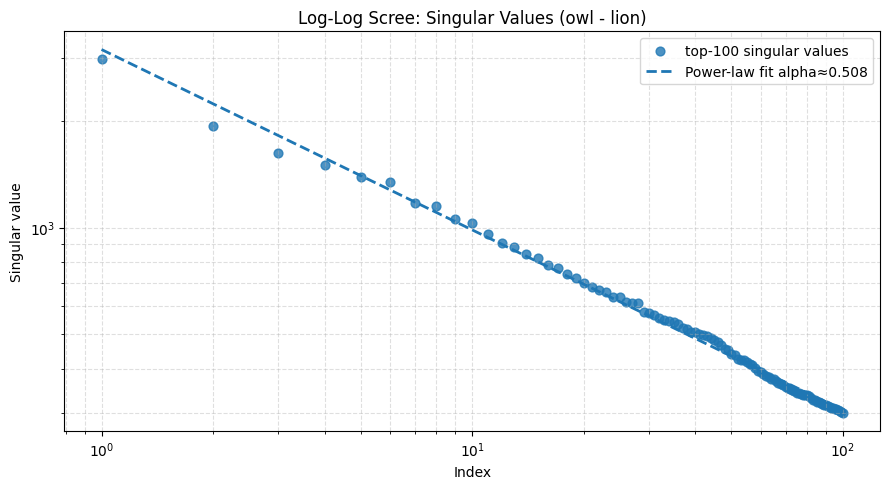

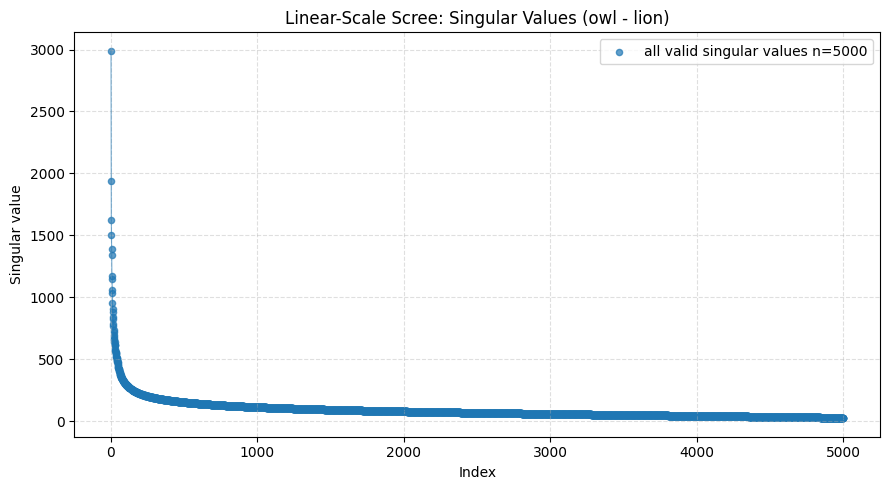


Variance explained by top components:
  SV1: 9.858%
  SV2: 4.136%
  SV3: 2.906%
  SV4: 2.497%


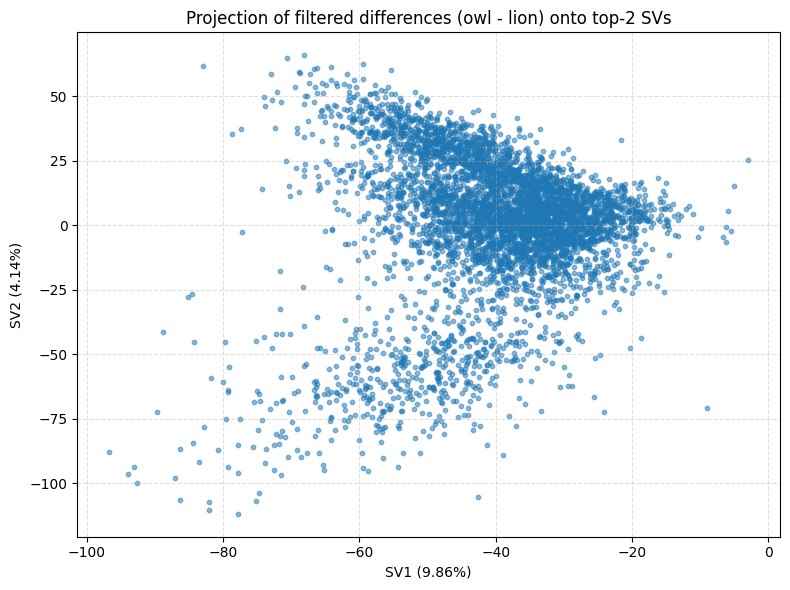


================= PIECEWISE LOGIT-LENS INTERPRETATION =================
Using lightweight logit-lens projector.
Loading tokenizer for unsloth/Qwen2.5-7B-Instruct...


Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Loading final norm and LM head tensors only...
Loaded norm tensor: model.norm.weight, shape=(3584,), dtype=torch.bfloat16
Loaded head tensor: model.embed_tokens.weight, shape=(152064, 3584), dtype=torch.bfloat16
Projection device: cuda
Hidden dim: 3584
LM head memory: 1.015 GiB
Apply final RMSNorm: False

--- SV 1 ---
Singular value: 2990.604248
Explained variance: 9.8577%

  >>> block 0
  Top tokens from logit lens:
   1. token_id=40399   token='inges'            logit= 0.0150 prob=0.000007
   2. token_id=110844  token='折磨'               logit= 0.0150 prob=0.000007
   3. token_id=115673  token='偏向'               logit= 0.0145 prob=0.000007
   4. token_id=17972   token='.concurrent'      logit= 0.0136 prob=0.000007
   5. token_id=30872   token=' ech'             logit= 0.0132 prob=0.000007
   6. token_id=47750   token=' viz'             logit= 0.0132 prob=0.000007
   7. token_id=58732   token='_sequences'       logit= 0.0131 prob=0.000007
   8. token_id=20955   token=' :-'             

In [ ]:
#!/usr/bin/env python3

# IMPORTANT:
# In Colab, run this before importing torch if possible.
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import gc
import glob
import json
from typing import List, Tuple, Union

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from transformers import AutoTokenizer
from huggingface_hub import snapshot_download
from safetensors import safe_open


# ============================================================
# EDIT THESE
# ============================================================

DATASETS = [
    (
        "lion",
        "/content/drive/MyDrive/subliminal-learning/results/hidden_state_last_layer/from_student_model/lion_extended_hidden_matrix_from_student_model.npy",
    ),
    (
        "owl",
        "/content/drive/MyDrive/subliminal-learning/results/hidden_state_last_layer/from_student_model/owl_extended_hidden_matrix_from_student_model.npy",
    ),
]

PAIRS: List[Tuple[Union[int, str], Union[int, str]]] = [
    ("lion", "owl"),
]

MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"

USE_COMBINED_MEAN = False

NUM_COMPONENTS = 4
TOP_K_SVS = 10
TOP_K_TOKENS = 15
POWERLAW_K = 100

# Extended matrix is 10 blocks × 3584 hidden dim each.
BLOCK_HIDDEN_DIM = 3584
EXPECTED_NUM_BLOCKS = 10

# Optional prefix metadata CSV.
PREFIX_META_CSV = None

# For logit-lens projection:
# "cuda" is faster and should use about 1-2 GB for Qwen2.5-7B lm_head.
# If you still hit GPU OOM, change this to "cpu".
PROJECTION_DEVICE = "cuda"

# Whether to apply final RMSNorm before LM head.
# For Qwen-style models, True is usually the faithful choice.
APPLY_FINAL_NORM = False

# ============================================================
# Utility
# ============================================================

def clear_cuda_cache():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


def load_matrix(filepath: str) -> np.ndarray:
    """
    Supports:
      - .npy extended matrices
      - .csv matrices with numeric columns

    Returns float32 ndarray.
    """
    ext = os.path.splitext(filepath)[1].lower()

    if ext == ".npy":
        arr = np.load(filepath)
        if arr.ndim != 2:
            raise RuntimeError(f"{filepath} is not a 2D array.")
        return arr.astype(np.float32, copy=False)

    if ext == ".csv":
        df = pd.read_csv(filepath)

        if "prompt_h" in df.columns:
            df = df.drop(columns=["prompt_h"])

        numeric_df = df.apply(pd.to_numeric, errors="coerce")
        numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
        valid_mask = numeric_df.notna().all(axis=1)
        numeric_df = numeric_df.loc[valid_mask].reset_index(drop=True)

        return numeric_df.values.astype(np.float32)

    raise ValueError(f"Unsupported file type: {filepath}")


def resolve_pair(pair, name_to_idx):
    a, b = pair

    if isinstance(a, str):
        if a not in name_to_idx:
            raise KeyError(f"Dataset name {a!r} not found.")
        a = name_to_idx[a]

    if isinstance(b, str):
        if b not in name_to_idx:
            raise KeyError(f"Dataset name {b!r} not found.")
        b = name_to_idx[b]

    return int(a), int(b)


def canonicalize_sign(vec: np.ndarray) -> np.ndarray:
    """
    SVD sign is arbitrary.
    Make the largest-magnitude entry positive.
    """
    idx = int(np.argmax(np.abs(vec)))
    if vec[idx] < 0:
        return -vec
    return vec


def project_out_mean_direction(D0: np.ndarray, mu: np.ndarray) -> np.ndarray:
    """
    Computes:

        D = D0 @ (I - mu mu^T / ||mu||^2)

    without explicitly forming the huge projection matrix.

    This avoids constructing a 35840 × 35840 matrix.
    """
    mu = mu.astype(np.float32, copy=False)
    mu_norm_sq = float(np.dot(mu, mu))

    if mu_norm_sq <= 0:
        print("Warning: mean vector norm is zero; skipping projection filter.")
        return D0.astype(np.float32, copy=False)

    # Each row x becomes x - ((x dot mu) / ||mu||^2) mu.
    coeffs = D0 @ mu
    coeffs = coeffs / mu_norm_sq

    D = D0 - coeffs[:, None] * mu[None, :]
    return D.astype(np.float32, copy=False)


def print_top_tokens_from_logits(logits_1d, tokenizer, top_k=15):
    probs = torch.softmax(logits_1d, dim=-1)
    topk = torch.topk(logits_1d, k=top_k)

    for rank, (logit, tok_id) in enumerate(
        zip(topk.values.tolist(), topk.indices.tolist()),
        start=1,
    ):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(
            f"  {rank:2d}. "
            f"token_id={tok_id:<7d} "
            f"token={repr(tok_str):<18s} "
            f"logit={logit: .4f} "
            f"prob={prob:.6f}"
        )


def print_bottom_tokens_from_logits(logits_1d, tokenizer, top_k=15):
    probs = torch.softmax(logits_1d, dim=-1)
    bottomk = torch.topk(-logits_1d, k=top_k)

    for rank, (neglogit, tok_id) in enumerate(
        zip(bottomk.values.tolist(), bottomk.indices.tolist()),
        start=1,
    ):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        logit = float(logits_1d[tok_id].item())
        prob = float(probs[tok_id].item())
        print(
            f"  {rank:2d}. "
            f"token_id={tok_id:<7d} "
            f"token={repr(tok_str):<18s} "
            f"logit={logit: .4f} "
            f"prob={prob:.6f}"
        )


# ============================================================
# Lightweight Qwen logit-lens projector
# ============================================================

class LightweightQwenLogitLens:
    """
    Loads only:
      - tokenizer
      - final RMSNorm weight
      - LM head / output embedding weight

    It does NOT load the full transformer stack.
    """

    def __init__(
        self,
        model_id: str,
        projection_device: str = "cuda",
        apply_final_norm: bool = True,
    ):
        self.model_id = model_id
        self.apply_final_norm = apply_final_norm

        if projection_device == "cuda" and not torch.cuda.is_available():
            print("CUDA requested but unavailable; falling back to CPU.")
            projection_device = "cpu"

        self.device = torch.device(projection_device)

        print(f"Loading tokenizer for {model_id}...")
        self.tokenizer = AutoTokenizer.from_pretrained(
            model_id,
            trust_remote_code=True,
        )

        print("Downloading / locating model safetensors...")
        self.model_dir = snapshot_download(
            model_id,
            allow_patterns=[
                "*.safetensors",
                "model.safetensors.index.json",
                "config.json",
                "tokenizer*",
                "vocab.json",
                "merges.txt",
                "special_tokens_map.json",
                "tokenizer_config.json",
                "chat_template.jinja",
            ],
        )

        config_path = os.path.join(self.model_dir, "config.json")
        with open(config_path, "r", encoding="utf-8") as f:
            self.config = json.load(f)

        self.rms_norm_eps = float(self.config.get("rms_norm_eps", 1e-6))

        print("Loading final norm and LM head tensors only...")

        norm_key, norm_weight = self._load_tensor_from_safetensors(
            [
                "model.norm.weight",
                "norm.weight",
                "transformer.ln_f.weight",
            ]
        )

        head_key, lm_head_weight = self._load_tensor_from_safetensors(
            [
                "lm_head.weight",
                "model.embed_tokens.weight",
                "transformer.wte.weight",
            ]
        )

        print(f"Loaded norm tensor: {norm_key}, shape={tuple(norm_weight.shape)}, dtype={norm_weight.dtype}")
        print(f"Loaded head tensor: {head_key}, shape={tuple(lm_head_weight.shape)}, dtype={lm_head_weight.dtype}")

        if norm_weight.ndim != 1:
            raise RuntimeError(f"Expected norm weight to be 1D, got shape {tuple(norm_weight.shape)}.")

        if lm_head_weight.ndim != 2:
            raise RuntimeError(f"Expected LM head weight to be 2D, got shape {tuple(lm_head_weight.shape)}.")

        if lm_head_weight.shape[1] != norm_weight.shape[0]:
            raise RuntimeError(
                "Hidden dimension mismatch: "
                f"lm_head_weight.shape={tuple(lm_head_weight.shape)}, "
                f"norm_weight.shape={tuple(norm_weight.shape)}"
            )

        self.hidden_dim = int(norm_weight.shape[0])

        # Put only the small needed projection tensors on GPU/CPU.
        self.norm_weight = norm_weight.to(device=self.device, dtype=torch.float32)

        if self.device.type == "cuda":
            self.lm_head_weight = lm_head_weight.to(device=self.device, dtype=torch.float16)
        else:
            # CPU float32 matmul is safer than CPU float16.
            self.lm_head_weight = lm_head_weight.to(device=self.device, dtype=torch.float32)

        del norm_weight
        del lm_head_weight
        clear_cuda_cache()

        head_mem_gib = (
            self.lm_head_weight.numel()
            * self.lm_head_weight.element_size()
            / 1024**3
        )

        print(f"Projection device: {self.device}")
        print(f"Hidden dim: {self.hidden_dim}")
        print(f"LM head memory: {head_mem_gib:.3f} GiB")
        print(f"Apply final RMSNorm: {self.apply_final_norm}")

    def _load_tensor_from_safetensors(self, candidate_keys):
        shard_paths = sorted(glob.glob(os.path.join(self.model_dir, "*.safetensors")))

        if not shard_paths:
            raise FileNotFoundError(f"No .safetensors files found in {self.model_dir}")

        for shard_path in shard_paths:
            with safe_open(shard_path, framework="pt", device="cpu") as f:
                keys = set(f.keys())
                for key in candidate_keys:
                    if key in keys:
                        tensor = f.get_tensor(key)
                        return key, tensor

        raise KeyError(f"Could not find any of these keys: {candidate_keys}")

    def qwen_rms_norm(self, x: torch.Tensor) -> torch.Tensor:
        """
        Manual RMSNorm:

            y = x / sqrt(mean(x^2) + eps) * weight
        """
        x_float = x.float()
        variance = x_float.pow(2).mean(dim=-1, keepdim=True)
        x_normed = x_float * torch.rsqrt(variance + self.rms_norm_eps)
        return x_normed * self.norm_weight

    @torch.no_grad()
    def vec_to_logits(self, v_np: np.ndarray) -> torch.Tensor:
        """
        Convert one hidden-direction vector to vocab logits.
        Returns CPU float32 logits.
        """
        if v_np.shape[-1] != self.hidden_dim:
            raise RuntimeError(
                f"Expected vector dim {self.hidden_dim}, got {v_np.shape[-1]}"
            )

        v = torch.tensor(
            v_np,
            device=self.device,
            dtype=torch.float32,
        ).unsqueeze(0)

        if self.apply_final_norm:
            v = self.qwen_rms_norm(v)

        v = v.to(dtype=self.lm_head_weight.dtype)

        logits = torch.matmul(v, self.lm_head_weight.t())

        return logits.squeeze(0).detach().float().cpu()


# ============================================================
# Main comparison
# ============================================================

def compare_pair(
    idx_a: int,
    idx_b: int,
    datasets: List[Tuple[str, str]],
    use_combined_mean: bool = False,
):
    name_a, path_a = datasets[idx_a]
    name_b, path_b = datasets[idx_b]

    print(f"\n=== Comparing {name_b!r} vs {name_a!r} ===")
    print(f"Index pair: {idx_b} vs {idx_a}")
    print("Loading matrices...")

    matrix_a = load_matrix(path_a)
    matrix_b = load_matrix(path_b)

    print(f"  {name_a} shape: {matrix_a.shape}")
    print(f"  {name_b} shape: {matrix_b.shape}")

    if matrix_a.shape != matrix_b.shape:
        raise RuntimeError(
            f"Shape mismatch: {name_a} {matrix_a.shape} vs {name_b} {matrix_b.shape}"
        )

    n_rows, n_cols = matrix_a.shape

    if n_cols % BLOCK_HIDDEN_DIM != 0:
        raise RuntimeError(
            f"Matrix width {n_cols} is not divisible by BLOCK_HIDDEN_DIM={BLOCK_HIDDEN_DIM}."
        )

    num_blocks = n_cols // BLOCK_HIDDEN_DIM
    print(f"  Detected {num_blocks} blocks of size {BLOCK_HIDDEN_DIM}.")

    if num_blocks != EXPECTED_NUM_BLOCKS:
        print(
            f"  Warning: expected {EXPECTED_NUM_BLOCKS} blocks, "
            f"but found {num_blocks}."
        )

    # D_0 = L_b - L_a.
    D0 = matrix_b - matrix_a

    if use_combined_mean:
        mu = (matrix_a.mean(axis=0) + matrix_b.mean(axis=0)) / 2.0
        mu_source = "combined mean"
    else:
        mu = matrix_a.mean(axis=0)
        mu_source = f"mean({name_a})"

    del matrix_a
    del matrix_b
    gc.collect()

    print(f"Applied mean source: {mu_source}")
    print("Projecting out mean direction without constructing full projection matrix...")
    D = project_out_mean_direction(D0, mu)

    del D0
    gc.collect()

    print("Performing SVD on filtered delta...")
    U, S, Vt = np.linalg.svd(D, full_matrices=False)

    print(f"\nTop {TOP_K_SVS} singular values for {name_b} - {name_a}:")
    for i in range(min(TOP_K_SVS, len(S))):
        print(f"  SV {i + 1}: {S[i]:.6f}")

    indices = np.arange(1, len(S) + 1)
    valid_mask = S > 1e-12
    S_valid = S[valid_mask]
    indices_valid = indices[valid_mask]

    k_fit = min(POWERLAW_K, len(S_valid))

    if k_fit < 2:
        alpha = np.nan
        C = np.nan
        indices_fit = None
        S_fit_vals = None
        print("Not enough valid singular values for power-law fit.")
    else:
        indices_fit = indices_valid[:k_fit]
        S_fit_vals = S_valid[:k_fit]

        log_indices = np.log(indices_fit)
        log_Svals = np.log(S_fit_vals)

        slope, intercept = np.polyfit(log_indices, log_Svals, deg=1)

        alpha = -slope
        C = np.exp(intercept)

        print(
            f"  -> Power-law fit using top {k_fit} singular values "
            f"indices 1..{indices_fit[-1]}."
        )
        print(f"  -> Estimated power-law exponent alpha: {alpha:.4f}")

    # ------------------------------------------------------------
    # Plot 1: log-log scree
    # ------------------------------------------------------------
    plt.figure(figsize=(9, 5))

    if k_fit >= 1:
        plt.scatter(
            indices_fit,
            S_fit_vals,
            label=f"top-{k_fit} singular values",
            alpha=0.8,
            s=40,
        )

        if not np.isnan(alpha):
            S_fit_line = C * (indices_fit ** (-alpha))
            plt.plot(
                indices_fit,
                S_fit_line,
                linestyle="--",
                linewidth=2,
                label=f"Power-law fit alpha≈{alpha:.3f}",
            )
    else:
        plt.text(
            0.5,
            0.5,
            "Not enough singular values to display top-k",
            ha="center",
            va="center",
            transform=plt.gca().transAxes,
        )

    plt.xscale("log")
    plt.yscale("log")
    plt.title(f"Log-Log Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index")
    plt.ylabel("Singular value")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # Plot 2: linear scree
    # ------------------------------------------------------------
    plt.figure(figsize=(9, 5))
    plt.scatter(
        indices_valid,
        S_valid,
        alpha=0.7,
        s=20,
        label=f"all valid singular values n={len(S_valid)}",
    )
    plt.plot(indices_valid, S_valid, linestyle="-", linewidth=0.8, alpha=0.6)
    plt.title(f"Linear-Scale Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index")
    plt.ylabel("Singular value")
    plt.legend()
    plt.grid(True, ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------
    # Top singular vectors
    # ------------------------------------------------------------
    num_components = min(NUM_COMPONENTS, Vt.shape[0])
    top_svecs = Vt[:num_components, :]

    explained_variance = (S**2) / np.sum(S**2)

    print("\nVariance explained by top components:")
    for i in range(num_components):
        print(f"  SV{i + 1}: {explained_variance[i] * 100:.3f}%")

    if top_svecs.shape[0] >= 2:
        projected = D.dot(top_svecs[:2, :].T)

        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5, s=10)
        plt.title(
            f"Projection of filtered differences ({name_b} - {name_a}) onto top-2 SVs"
        )
        plt.xlabel(f"SV1 ({explained_variance[0] * 100:.2f}%)")
        plt.ylabel(f"SV2 ({explained_variance[1] * 100:.2f}%)")
        plt.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough singular vectors to project to 2D.")

    # ------------------------------------------------------------
    # Piecewise logit-lens interpretation
    # ------------------------------------------------------------
    print("\n================= PIECEWISE LOGIT-LENS INTERPRETATION =================")
    print("Using lightweight logit-lens projector.")

    clear_cuda_cache()

    projector = LightweightQwenLogitLens(
        MODEL_ID,
        projection_device=PROJECTION_DEVICE,
        apply_final_norm=APPLY_FINAL_NORM,
    )

    if projector.hidden_dim != BLOCK_HIDDEN_DIM:
        raise RuntimeError(
            f"Projector hidden dim {projector.hidden_dim} does not match "
            f"BLOCK_HIDDEN_DIM={BLOCK_HIDDEN_DIM}."
        )

    tokenizer = projector.tokenizer

    # Load prefix labels if provided.
    prefix_labels = None

    if PREFIX_META_CSV and os.path.exists(PREFIX_META_CSV):
        try:
            meta_df = pd.read_csv(PREFIX_META_CSV)
            if "prefix_string" in meta_df.columns:
                prefix_labels = meta_df["prefix_string"].tolist()
                print(f"Loaded {len(prefix_labels)} prefix labels from {PREFIX_META_CSV}")
        except Exception as e:
            print(f"Warning: could not load prefix meta CSV: {e}")

    for i in range(num_components):
        full_vec = canonicalize_sign(top_svecs[i].copy())

        print(f"\n--- SV {i + 1} ---")
        print(f"Singular value: {S[i]:.6f}")
        print(f"Explained variance: {explained_variance[i] * 100:.4f}%")

        for block_idx in range(num_blocks):
            start = block_idx * BLOCK_HIDDEN_DIM
            end = (block_idx + 1) * BLOCK_HIDDEN_DIM
            chunk = full_vec[start:end]

            logits_dir = projector.vec_to_logits(chunk)

            label = f"block {block_idx}"

            if prefix_labels is not None and block_idx < len(prefix_labels):
                label = f"block {block_idx} | prefix={repr(prefix_labels[block_idx])}"

            print(f"\n  >>> {label}")
            print("  Top tokens from logit lens:")
            print_top_tokens_from_logits(
                logits_dir,
                tokenizer,
                top_k=TOP_K_TOKENS,
            )

            print("  Bottom tokens from logit lens:")
            print_bottom_tokens_from_logits(
                logits_dir,
                tokenizer,
                top_k=TOP_K_TOKENS,
            )

    return {
        "name_a": name_a,
        "name_b": name_b,
        "D": D,
        "U": U,
        "S": S,
        "Vt": Vt,
        "explained_variance": explained_variance,
        "mu": mu,
    }


# ============================================================
# Entry point
# ============================================================

if __name__ == "__main__":
    clear_cuda_cache()

    name_to_idx = {
        name: idx
        for idx, (name, _) in enumerate(DATASETS)
    }

    all_results = {}

    for pair in PAIRS:
        ia, ib = resolve_pair(pair, name_to_idx)
        result = compare_pair(
            ia,
            ib,
            DATASETS,
            use_combined_mean=USE_COMBINED_MEAN,
        )

        key = f"{result['name_b']}_minus_{result['name_a']}"
        all_results[key] = result

    print("\nDone.")

Possibly more correct version


=== Comparing 'control' vs 'mixed_animal' (indices 0 vs 1) ===
Loading matrices...
  mixed_animal shape: (5000, 35840)
  control shape: (5000, 35840)
  Detected 10 blocks of size 3584.
Applied projection filter using mean(mixed_animal).
Performing SVD on filtered delta...

Top 10 singular values (for control - mixed_animal):
  SV 1: 29587.699219
  SV 2: 15743.442383
  SV 3: 11844.437500
  SV 4: 10026.412109
  SV 5: 9557.597656
  SV 6: 8651.302734
  SV 7: 8419.877930
  SV 8: 8169.387695
  SV 9: 7499.663574
  SV 10: 7213.292480
  -> Power-law fit using top 100 singular values (indices 1..100).
  -> Estimated Power Law Exponent (alpha): 0.6330


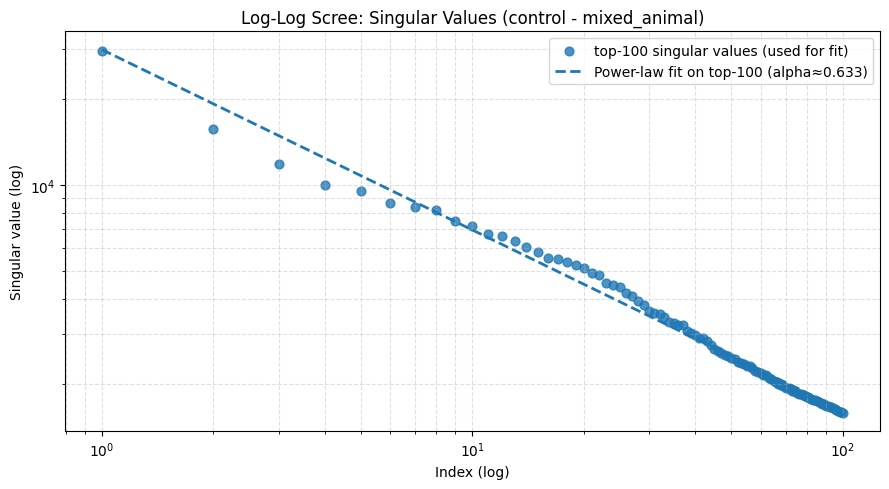

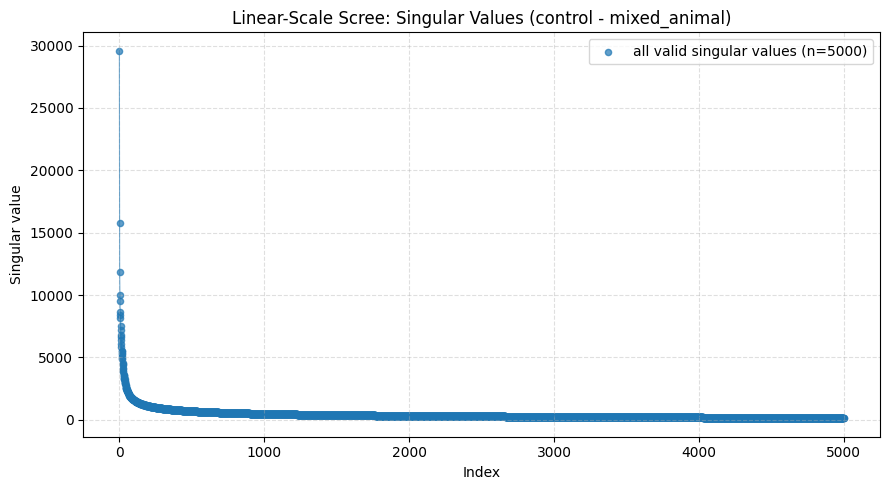


Variance explained by top components:
  SV1: 24.877%
  SV2: 7.043%
  SV3: 3.987%
  SV4: 2.857%


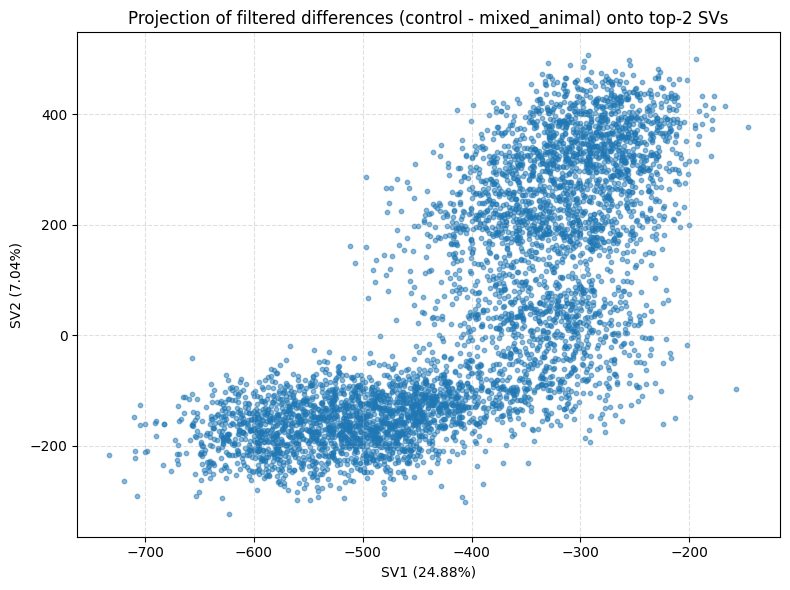


================= PIECEWISE LOGIT-LENS INTERPRETATION =================
Loading model for projection...


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Using final norm module: Qwen2RMSNorm

--- SV 1 ---
Singular value: 29587.699219
Explained variance: 24.8772%

  >>> block 0
  Top tokens from logit lens:
   1. token_id=198     token='\n'             logit= 12.0547 prob=0.868320
   2. token_id=151643  token='<|endoftext|>'  logit= 10.0781 prob=0.120301
   3. token_id=715     token=' \n'            logit= 7.1094 prob=0.006180
   4. token_id=624     token='.\n'            logit= 6.0469 prob=0.002136
   5. token_id=8997    token='。\n'            logit= 4.6797 prob=0.000544
   6. token_id=1406    token='\n\n\n'         logit= 3.9883 prob=0.000273
   7. token_id=5267    token='?\n'            logit= 3.7930 prob=0.000224
   8. token_id=698     token='"\n'            logit= 3.6934 prob=0.000203
   9. token_id=16448   token=' .\n'           logit= 3.3828 prob=0.000149
  10. token_id=220     token=' '              logit= 3.2129 prob=0.000126
  11. token_id=6913    token='-\n'            logit= 3.1699 prob=0.000120
  12. token_id=271     token=

In [ ]:
#!/usr/bin/env python3
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from typing import List, Tuple, Union

# -----------------------------
# EDIT THESE
# -----------------------------
DATASETS = [
    ("control",  '/content/drive/MyDrive/subliminal-learning/extended_hidden_matrix_0_to_9_mixed_animal_control_on_owl_all_space_separated_no_strict_repeats_v2.npy'),
    ("mixed_animal", '/content/drive/MyDrive/subliminal-learning/extended_hidden_matrix_0_to_9_mixed_animal_extrapolated_models_t_16_on_owl_all_space_separated_no_strict_repeats_v2.npy'),
]

PAIRS: List[Tuple[Union[int, str], Union[int, str]]] = [
    ("mixed_animal", "control"),
]

MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"

USE_COMBINED_MEAN = False

NUM_COMPONENTS = 4
TOP_K_SVS = 10
TOP_K_TOKENS = 15
POWERLAW_K = 100

# Extended matrix is 10 blocks × 3584 hidden dim each
BLOCK_HIDDEN_DIM = 3584
EXPECTED_NUM_BLOCKS = 10

# Optional: if you saved prefix metadata CSV alongside the .npy file
# the script will use it only for nicer labels.
PREFIX_META_CSV = None
# Example:
# PREFIX_META_CSV = "/content/drive/MyDrive/subliminal-learning/results/hidden_state_last_layer/lion_extended_hidden_matrix_meta.csv"
# -----------------------------
# End edit section
# -----------------------------


def load_matrix(filepath: str) -> np.ndarray:
    """
    Supports:
      - .npy extended matrices
      - .csv matrices with only numeric columns
    Returns float32 ndarray.
    """
    ext = os.path.splitext(filepath)[1].lower()

    if ext == ".npy":
        arr = np.load(filepath)
        if arr.ndim != 2:
            raise RuntimeError(f"{filepath} is not a 2D array.")
        return arr.astype(np.float32, copy=False)

    if ext == ".csv":
        df = pd.read_csv(filepath)

        # Support older files with prompt_h
        if "prompt_h" in df.columns:
            df = df.drop(columns=["prompt_h"])

        numeric_df = df.apply(pd.to_numeric, errors="coerce")
        numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
        valid_mask = numeric_df.notna().all(axis=1)
        numeric_df = numeric_df.loc[valid_mask].reset_index(drop=True)
        return numeric_df.values.astype(np.float32)

    raise ValueError(f"Unsupported file type: {filepath}")


def resolve_pair(pair, name_to_idx):
    a, b = pair
    if isinstance(a, str):
        if a not in name_to_idx:
            raise KeyError(f"Dataset name '{a}' not found.")
        a = name_to_idx[a]
    if isinstance(b, str):
        if b not in name_to_idx:
            raise KeyError(f"Dataset name '{b}' not found.")
        b = name_to_idx[b]
    return int(a), int(b)


def get_final_norm_module(model):
    candidates = [
        getattr(getattr(model, "model", None), "norm", None),
        getattr(getattr(model, "transformer", None), "ln_f", None),
        getattr(model, "norm", None),
        getattr(getattr(model, "model", None), "final_layernorm", None),
    ]
    for c in candidates:
        if c is not None:
            return c
    return None


def get_output_embedding_module(model):
    out = model.get_output_embeddings()
    if out is not None:
        return out
    if hasattr(model, "lm_head"):
        return model.lm_head
    raise RuntimeError("Could not find output embeddings / lm head.")


def module_device_and_dtype(module):
    for p in module.parameters():
        return p.device, p.dtype
    for b in module.buffers():
        return b.device, b.dtype
    raise RuntimeError(f"Could not determine device/dtype for module {type(module).__name__}")


def print_top_tokens_from_logits(logits_1d, tokenizer, top_k=15):
    probs = torch.softmax(logits_1d, dim=-1)
    topk = torch.topk(logits_1d, k=top_k)

    for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(f"  {rank:2d}. token_id={tok_id:<7d} token={repr(tok_str):<16s} logit={logit: .4f} prob={prob:.6f}")


def canonicalize_sign(vec: np.ndarray) -> np.ndarray:
    """
    SVD sign is arbitrary. Make the largest-magnitude entry positive.
    """
    idx = int(np.argmax(np.abs(vec)))
    if vec[idx] < 0:
        return -vec
    return vec


def compare_pair(idx_a: int, idx_b: int, datasets: List[Tuple[str, str]], use_combined_mean: bool = False):
    name_a, path_a = datasets[idx_a]
    name_b, path_b = datasets[idx_b]
    print(f"\n=== Comparing '{name_b}' vs '{name_a}' (indices {idx_b} vs {idx_a}) ===")
    print("Loading matrices...")

    matrix_a = load_matrix(path_a)
    matrix_b = load_matrix(path_b)

    print(f"  {name_a} shape: {matrix_a.shape}")
    print(f"  {name_b} shape: {matrix_b.shape}")

    if matrix_a.shape != matrix_b.shape:
        raise RuntimeError(f"Shape mismatch: {name_a} {matrix_a.shape} vs {name_b} {matrix_b.shape}")

    n_rows, n_cols = matrix_a.shape
    if n_cols % BLOCK_HIDDEN_DIM != 0:
        raise RuntimeError(
            f"Matrix width {n_cols} is not divisible by BLOCK_HIDDEN_DIM={BLOCK_HIDDEN_DIM}."
        )

    num_blocks = n_cols // BLOCK_HIDDEN_DIM
    print(f"  Detected {num_blocks} blocks of size {BLOCK_HIDDEN_DIM}.")
    if num_blocks != EXPECTED_NUM_BLOCKS:
        print(f"  Warning: expected {EXPECTED_NUM_BLOCKS} blocks, but found {num_blocks}.")

    # D_0 = L - L'
    D_0 = matrix_b - matrix_a

    # compute mu
    if use_combined_mean:
        mu = np.vstack([matrix_a, matrix_b]).mean(axis=0)
        mu_source = "combined mean (L & L')"
    else:
        mu = matrix_a.mean(axis=0)
        mu_source = f"mean({name_a})"

    mu_norm_sq = float(np.dot(mu, mu))
    if mu_norm_sq <= 0:
        print("Warning: mean vector norm is zero; skipping projection filter.")
        projection_filter = np.eye(len(mu), dtype=np.float32)
    else:
        P_mu = np.outer(mu, mu) / mu_norm_sq
        projection_filter = np.eye(len(mu), dtype=np.float32) - P_mu

    D = D_0.dot(projection_filter)

    print(f"Applied projection filter using {mu_source}.")
    print("Performing SVD on filtered delta...")
    U, S, Vt = np.linalg.svd(D, full_matrices=False)

    print(f"\nTop {TOP_K_SVS} singular values (for {name_b} - {name_a}):")
    for i in range(min(TOP_K_SVS, len(S))):
        print(f"  SV {i+1}: {S[i]:.6f}")

    indices = np.arange(1, len(S) + 1)
    valid_mask = S > 1e-12
    S_valid = S[valid_mask]
    indices_valid = indices[valid_mask]

    k_fit = min(POWERLAW_K, len(S_valid))
    if k_fit < 2:
        alpha = np.nan
        C = np.nan
        print("Not enough valid singular values for power-law fit.")
        indices_fit = None
        S_fit_vals = None
    else:
        indices_fit = indices_valid[:k_fit]
        S_fit_vals = S_valid[:k_fit]
        log_indices = np.log(indices_fit)
        log_Svals = np.log(S_fit_vals)
        slope, intercept = np.polyfit(log_indices, log_Svals, deg=1)
        alpha = -slope
        C = np.exp(intercept)
        print(f"  -> Power-law fit using top {k_fit} singular values (indices 1..{indices_fit[-1]}).")
        print(f"  -> Estimated Power Law Exponent (alpha): {alpha:.4f}")

    # Plot 1: LOG-LOG
    plt.figure(figsize=(9, 5))
    if k_fit >= 1:
        plt.scatter(
            indices_fit,
            S_fit_vals,
            label=f"top-{k_fit} singular values (used for fit)",
            alpha=0.8,
            s=40,
        )
        if not np.isnan(alpha):
            S_fit_line = C * (indices_fit ** (-alpha))
            plt.plot(
                indices_fit,
                S_fit_line,
                linestyle="--",
                linewidth=2,
                label=f"Power-law fit on top-{k_fit} (alpha≈{alpha:.3f})",
            )
    else:
        plt.text(
            0.5,
            0.5,
            "Not enough singular values to display top-k",
            ha="center",
            va="center",
            transform=plt.gca().transAxes,
        )

    plt.xscale("log")
    plt.yscale("log")
    plt.title(f"Log-Log Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index (log)")
    plt.ylabel("Singular value (log)")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    # Plot 2: linear scale
    plt.figure(figsize=(9, 5))
    plt.scatter(indices_valid, S_valid, alpha=0.7, s=20, label=f"all valid singular values (n={len(S_valid)})")
    plt.plot(indices_valid, S_valid, linestyle="-", linewidth=0.8, alpha=0.6)
    plt.title(f"Linear-Scale Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index")
    plt.ylabel("Singular value")
    plt.legend()
    plt.grid(True, ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    num_components = NUM_COMPONENTS
    top_svecs = Vt[:num_components, :]
    explained_variance = (S**2) / np.sum(S**2)

    print("\nVariance explained by top components:")
    for i in range(min(num_components, len(explained_variance))):
        print(f"  SV{i+1}: {explained_variance[i]*100:.3f}%")

    if top_svecs.shape[0] >= 2:
        projected = D.dot(top_svecs[:2, :].T)
        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5, s=10)
        plt.title(f"Projection of filtered differences ({name_b} - {name_a}) onto top-2 SVs")
        plt.xlabel(f"SV1 ({explained_variance[0]*100:.2f}%)")
        plt.ylabel(f"SV2 ({explained_variance[1]*100:.2f}%)")
        plt.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough singular vectors to project to 2D.")

    # -----------------------------
    # Piecewise logit-lens interpretation
    # -----------------------------
    print("\n================= PIECEWISE LOGIT-LENS INTERPRETATION =================")
    print("Loading model for projection...")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto",
        trust_remote_code=True,
    )
    model.eval()

    out_emb = get_output_embedding_module(model)
    final_norm = get_final_norm_module(model)

    out_device, out_dtype = module_device_and_dtype(out_emb)
    if final_norm is not None:
        norm_device, norm_dtype = module_device_and_dtype(final_norm)
        print(f"Using final norm module: {type(final_norm).__name__}")
    else:
        norm_device, norm_dtype = out_device, out_dtype
        print("Warning: no final norm module found; projecting vectors directly.")

    def vec_to_logits(v_np: np.ndarray) -> torch.Tensor:
        """
        Convert one 3584-d vector to vocab logits.
        """
        v = torch.tensor(v_np, device=norm_device, dtype=norm_dtype).unsqueeze(0)  # [1, D]
        if final_norm is not None:
            v = final_norm(v)
        v = v.to(device=out_device, dtype=out_dtype)
        logits = torch.matmul(v, out_emb.weight.t())  # [1, vocab]
        if getattr(out_emb, "bias", None) is not None:
            logits = logits + out_emb.bias
        return logits.squeeze(0).detach().float().cpu()

    # Load prefix labels if provided
    prefix_labels = None
    if PREFIX_META_CSV and os.path.exists(PREFIX_META_CSV):
        try:
            meta_df = pd.read_csv(PREFIX_META_CSV)
            if "prefix_string" in meta_df.columns:
                prefix_labels = meta_df["prefix_string"].tolist()
                print(f"Loaded {len(prefix_labels)} prefix labels from {PREFIX_META_CSV}")
        except Exception as e:
            print(f"Warning: could not load prefix meta CSV: {e}")

    for i in range(min(num_components, top_svecs.shape[0])):
        full_vec = canonicalize_sign(top_svecs[i].copy())

        print(f"\n--- SV {i+1} ---")
        print(f"Singular value: {S[i]:.6f}")
        print(f"Explained variance: {explained_variance[i]*100:.4f}%")

        for block_idx in range(num_blocks):
            start = block_idx * BLOCK_HIDDEN_DIM
            end = (block_idx + 1) * BLOCK_HIDDEN_DIM
            chunk = full_vec[start:end]

            logits_dir = vec_to_logits(chunk)

            label = f"block {block_idx}"
            if prefix_labels is not None and block_idx < len(prefix_labels):
                label = f"block {block_idx} | prefix={repr(prefix_labels[block_idx])}"

            print(f"\n  >>> {label}")
            print("  Top tokens from logit lens:")
            print_top_tokens_from_logits(logits_dir, tokenizer, top_k=TOP_K_TOKENS)

            bottomk = torch.topk(-logits_dir, k=TOP_K_TOKENS)
            probs = torch.softmax(logits_dir, dim=-1)

            print("  Bottom tokens from logit lens:")
            for rank, (neglogit, tok_id) in enumerate(zip(bottomk.values.tolist(), bottomk.indices.tolist()), start=1):
                tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
                logit = float(logits_dir[tok_id].item())
                prob = float(probs[tok_id].item())
                print(f"    {rank:2d}. token_id={tok_id:<7d} token={repr(tok_str):<16s} logit={logit: .4f} prob={prob:.6f}")

    return {
        "name_a": name_a,
        "name_b": name_b,
        "D": D,
        "U": U,
        "S": S,
        "Vt": Vt,
        "explained_variance": explained_variance,
        "mu": mu,
    }


if __name__ == "__main__":
    name_to_idx = {name: idx for idx, (name, _) in enumerate(DATASETS)}

    for pair in PAIRS:
        ia, ib = resolve_pair(pair, name_to_idx)
        compare_pair(ia, ib, DATASETS, use_combined_mean=USE_COMBINED_MEAN)

## SVD and logit-lens for simple hidden state matrix


=== Comparing 'owl' vs 'penguin' (indices 1 vs 0) ===
Loading matrices...
  penguin shape: (5000, 3584)
  owl shape: (5000, 3584)
  Detected 1 blocks of size 3584.
Applied projection filter using mean(penguin).
Performing SVD on filtered delta...

Top 10 singular values (for owl - penguin):
  SV 1: 2561.464600
  SV 2: 855.256714
  SV 3: 674.560242
  SV 4: 425.573578
  SV 5: 400.800629
  SV 6: 342.290039
  SV 7: 286.570343
  SV 8: 271.893005
  SV 9: 264.100861
  SV 10: 259.026947
  -> Power-law fit using top 100 singular values (indices 1..100).
  -> Estimated Power Law Exponent (alpha): 0.6541


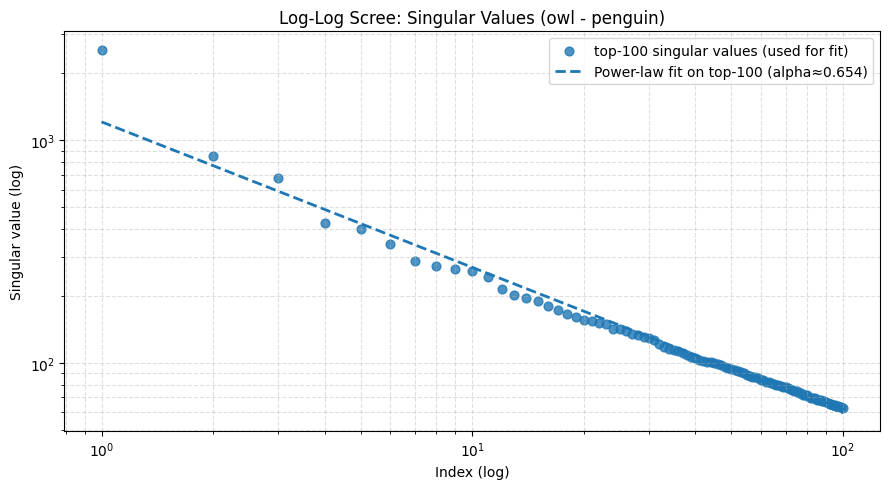

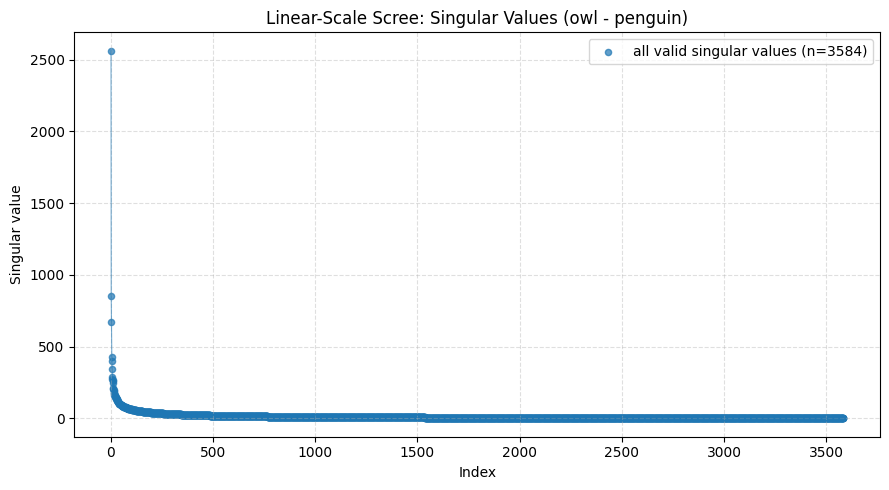


Variance explained by top components:
  SV1: 64.311%
  SV2: 7.170%
  SV3: 4.460%
  SV4: 1.775%


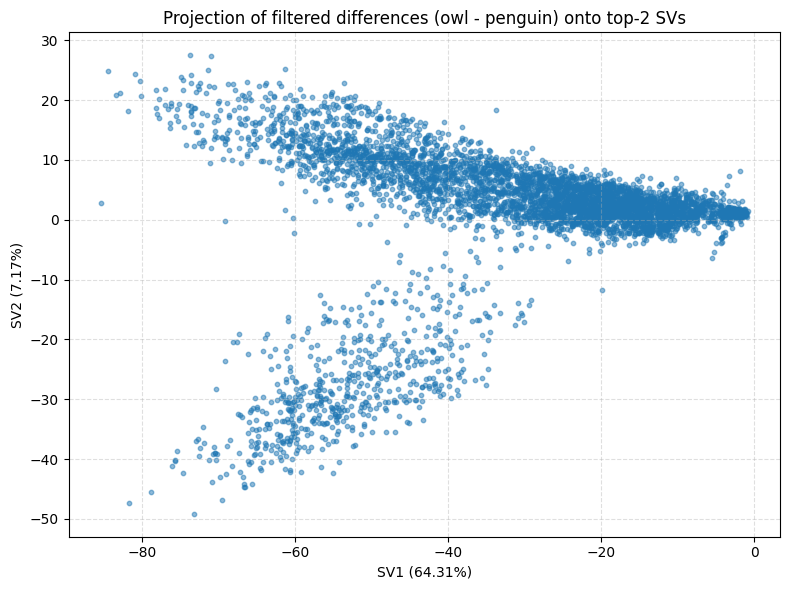


================= PIECEWISE LOGIT-LENS INTERPRETATION =================
Loading model for projection...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Using final norm module: Qwen2RMSNorm

--- SV 1 ---
Singular value: 2561.464600
Explained variance: 64.3109%

  >>> block 0
  Top tokens from logit lens:
   1. token_id=15570   token=' ow'            logit= 39.8438 prob=0.876711
   2. token_id=52269   token=' owl'           logit= 37.8750 prob=0.122416
   3. token_id=28869   token=' OW'            logit= 32.5312 prob=0.000585
   4. token_id=73695   token=' Owl'           logit= 30.9688 prob=0.000123
   5. token_id=40796   token=' Ow'            logit= 30.9219 prob=0.000117
   6. token_id=68618   token='/owl'           logit= 29.3594 prob=0.000025
   7. token_id=9605    token='owl'            logit= 28.6719 prob=0.000012
   8. token_id=91525   token='.owl'           logit= 27.7188 prob=0.000005
   9. token_id=363     token='ow'             logit= 27.4531 prob=0.000004
  10. token_id=69819   token='_OW'            logit= 26.9219 prob=0.000002
  11. token_id=3307    token='OW'             logit= 24.2344 prob=0.000000
  12. token_id=63357 

In [11]:
#!/usr/bin/env python3
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from typing import List, Tuple, Union

# -----------------------------
# EDIT THESE
# -----------------------------
DATASETS = [
    ("penguin",  '/content/drive/MyDrive/subliminal-learning/penguin_simple_from_teacher_test.csv'),
    ("owl", '/content/drive/MyDrive/subliminal-learning/owl_simple_from_teacher_test.csv'),
]

PAIRS: List[Tuple[Union[int, str], Union[int, str]]] = [
    ("penguin", "owl"),
]

MODEL_ID = "unsloth/Qwen2.5-7B-Instruct"

USE_COMBINED_MEAN = False

NUM_COMPONENTS = 4
TOP_K_SVS = 10
TOP_K_TOKENS = 15
POWERLAW_K = 100

# Extended matrix is 10 blocks × 3584 hidden dim each
BLOCK_HIDDEN_DIM = 3584
# EXPECTED_NUM_BLOCKS = 10
EXPECTED_NUM_BLOCKS = 1

# Optional: if you saved prefix metadata CSV alongside the .npy file
# the script will use it only for nicer labels.
PREFIX_META_CSV = None
# Example:
# PREFIX_META_CSV = "/content/drive/MyDrive/subliminal-learning/results/hidden_state_last_layer/lion_extended_hidden_matrix_meta.csv"
# -----------------------------
# End edit section
# -----------------------------


def load_matrix(filepath: str) -> np.ndarray:
    """
    Supports:
      - .npy extended matrices
      - .csv matrices with only numeric columns
    Returns float32 ndarray.
    """
    ext = os.path.splitext(filepath)[1].lower()

    if ext == ".npy":
        arr = np.load(filepath)
        if arr.ndim != 2:
            raise RuntimeError(f"{filepath} is not a 2D array.")
        return arr.astype(np.float32, copy=False)

    if ext == ".csv":
        df = pd.read_csv(filepath)

        # Support older files with prompt_h
        if "prompt_h" in df.columns:
            df = df.drop(columns=["prompt_h"])

        numeric_df = df.apply(pd.to_numeric, errors="coerce")
        numeric_df.replace([np.inf, -np.inf], np.nan, inplace=True)
        valid_mask = numeric_df.notna().all(axis=1)
        numeric_df = numeric_df.loc[valid_mask].reset_index(drop=True)
        return numeric_df.values.astype(np.float32)

    raise ValueError(f"Unsupported file type: {filepath}")


def resolve_pair(pair, name_to_idx):
    a, b = pair
    if isinstance(a, str):
        if a not in name_to_idx:
            raise KeyError(f"Dataset name '{a}' not found.")
        a = name_to_idx[a]
    if isinstance(b, str):
        if b not in name_to_idx:
            raise KeyError(f"Dataset name '{b}' not found.")
        b = name_to_idx[b]
    return int(a), int(b)


def get_final_norm_module(model):
    candidates = [
        getattr(getattr(model, "model", None), "norm", None),
        getattr(getattr(model, "transformer", None), "ln_f", None),
        getattr(model, "norm", None),
        getattr(getattr(model, "model", None), "final_layernorm", None),
    ]
    for c in candidates:
        if c is not None:
            return c
    return None


def get_output_embedding_module(model):
    out = model.get_output_embeddings()
    if out is not None:
        return out
    if hasattr(model, "lm_head"):
        return model.lm_head
    raise RuntimeError("Could not find output embeddings / lm head.")


def module_device_and_dtype(module):
    for p in module.parameters():
        return p.device, p.dtype
    for b in module.buffers():
        return b.device, b.dtype
    raise RuntimeError(f"Could not determine device/dtype for module {type(module).__name__}")


def print_top_tokens_from_logits(logits_1d, tokenizer, top_k=15):
    probs = torch.softmax(logits_1d, dim=-1)
    topk = torch.topk(logits_1d, k=top_k)

    for rank, (logit, tok_id) in enumerate(zip(topk.values.tolist(), topk.indices.tolist()), start=1):
        tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
        prob = float(probs[tok_id].item())
        print(f"  {rank:2d}. token_id={tok_id:<7d} token={repr(tok_str):<16s} logit={logit: .4f} prob={prob:.6f}")


def canonicalize_sign(vec: np.ndarray) -> np.ndarray:
    """
    SVD sign is arbitrary. Make the largest-magnitude entry positive.
    """
    idx = int(np.argmax(np.abs(vec)))
    if vec[idx] < 0:
        return -vec
    return vec


def compare_pair(idx_a: int, idx_b: int, datasets: List[Tuple[str, str]], use_combined_mean: bool = False):
    name_a, path_a = datasets[idx_a]
    name_b, path_b = datasets[idx_b]
    print(f"\n=== Comparing '{name_b}' vs '{name_a}' (indices {idx_b} vs {idx_a}) ===")
    print("Loading matrices...")

    matrix_a = load_matrix(path_a)
    matrix_b = load_matrix(path_b)

    print(f"  {name_a} shape: {matrix_a.shape}")
    print(f"  {name_b} shape: {matrix_b.shape}")

    if matrix_a.shape != matrix_b.shape:
        raise RuntimeError(f"Shape mismatch: {name_a} {matrix_a.shape} vs {name_b} {matrix_b.shape}")

    n_rows, n_cols = matrix_a.shape
    if n_cols % BLOCK_HIDDEN_DIM != 0:
        raise RuntimeError(
            f"Matrix width {n_cols} is not divisible by BLOCK_HIDDEN_DIM={BLOCK_HIDDEN_DIM}."
        )

    num_blocks = n_cols // BLOCK_HIDDEN_DIM
    print(f"  Detected {num_blocks} blocks of size {BLOCK_HIDDEN_DIM}.")
    if num_blocks != EXPECTED_NUM_BLOCKS:
        print(f"  Warning: expected {EXPECTED_NUM_BLOCKS} blocks, but found {num_blocks}.")

    # D_0 = L - L'
    D_0 = matrix_b - matrix_a

    # compute mu
    if use_combined_mean:
        mu = np.vstack([matrix_a, matrix_b]).mean(axis=0)
        mu_source = "combined mean (L & L')"
    else:
        mu = matrix_a.mean(axis=0)
        mu_source = f"mean({name_a})"

    mu_norm_sq = float(np.dot(mu, mu))
    if mu_norm_sq <= 0:
        print("Warning: mean vector norm is zero; skipping projection filter.")
        projection_filter = np.eye(len(mu), dtype=np.float32)
    else:
        P_mu = np.outer(mu, mu) / mu_norm_sq
        projection_filter = np.eye(len(mu), dtype=np.float32) - P_mu

    D = D_0.dot(projection_filter)

    print(f"Applied projection filter using {mu_source}.")
    print("Performing SVD on filtered delta...")
    U, S, Vt = np.linalg.svd(D, full_matrices=False)

    print(f"\nTop {TOP_K_SVS} singular values (for {name_b} - {name_a}):")
    for i in range(min(TOP_K_SVS, len(S))):
        print(f"  SV {i+1}: {S[i]:.6f}")

    indices = np.arange(1, len(S) + 1)
    valid_mask = S > 1e-12
    S_valid = S[valid_mask]
    indices_valid = indices[valid_mask]

    k_fit = min(POWERLAW_K, len(S_valid))
    if k_fit < 2:
        alpha = np.nan
        C = np.nan
        print("Not enough valid singular values for power-law fit.")
        indices_fit = None
        S_fit_vals = None
    else:
        indices_fit = indices_valid[:k_fit]
        S_fit_vals = S_valid[:k_fit]
        log_indices = np.log(indices_fit)
        log_Svals = np.log(S_fit_vals)
        slope, intercept = np.polyfit(log_indices, log_Svals, deg=1)
        alpha = -slope
        C = np.exp(intercept)
        print(f"  -> Power-law fit using top {k_fit} singular values (indices 1..{indices_fit[-1]}).")
        print(f"  -> Estimated Power Law Exponent (alpha): {alpha:.4f}")

    # Plot 1: LOG-LOG
    plt.figure(figsize=(9, 5))
    if k_fit >= 1:
        plt.scatter(
            indices_fit,
            S_fit_vals,
            label=f"top-{k_fit} singular values (used for fit)",
            alpha=0.8,
            s=40,
        )
        if not np.isnan(alpha):
            S_fit_line = C * (indices_fit ** (-alpha))
            plt.plot(
                indices_fit,
                S_fit_line,
                linestyle="--",
                linewidth=2,
                label=f"Power-law fit on top-{k_fit} (alpha≈{alpha:.3f})",
            )
    else:
        plt.text(
            0.5,
            0.5,
            "Not enough singular values to display top-k",
            ha="center",
            va="center",
            transform=plt.gca().transAxes,
        )

    plt.xscale("log")
    plt.yscale("log")
    plt.title(f"Log-Log Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index (log)")
    plt.ylabel("Singular value (log)")
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    # Plot 2: linear scale
    plt.figure(figsize=(9, 5))
    plt.scatter(indices_valid, S_valid, alpha=0.7, s=20, label=f"all valid singular values (n={len(S_valid)})")
    plt.plot(indices_valid, S_valid, linestyle="-", linewidth=0.8, alpha=0.6)
    plt.title(f"Linear-Scale Scree: Singular Values ({name_b} - {name_a})")
    plt.xlabel("Index")
    plt.ylabel("Singular value")
    plt.legend()
    plt.grid(True, ls="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

    num_components = NUM_COMPONENTS
    top_svecs = Vt[:num_components, :]
    explained_variance = (S**2) / np.sum(S**2)

    print("\nVariance explained by top components:")
    for i in range(min(num_components, len(explained_variance))):
        print(f"  SV{i+1}: {explained_variance[i]*100:.3f}%")

    if top_svecs.shape[0] >= 2:
        projected = D.dot(top_svecs[:2, :].T)
        plt.figure(figsize=(8, 6))
        plt.scatter(projected[:, 0], projected[:, 1], alpha=0.5, s=10)
        plt.title(f"Projection of filtered differences ({name_b} - {name_a}) onto top-2 SVs")
        plt.xlabel(f"SV1 ({explained_variance[0]*100:.2f}%)")
        plt.ylabel(f"SV2 ({explained_variance[1]*100:.2f}%)")
        plt.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough singular vectors to project to 2D.")

    # -----------------------------
    # Piecewise logit-lens interpretation
    # -----------------------------
    print("\n================= PIECEWISE LOGIT-LENS INTERPRETATION =================")
    print("Loading model for projection...")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto",
        trust_remote_code=True,
    )
    model.eval()

    out_emb = get_output_embedding_module(model)
    final_norm = get_final_norm_module(model)

    out_device, out_dtype = module_device_and_dtype(out_emb)
    if final_norm is not None:
        norm_device, norm_dtype = module_device_and_dtype(final_norm)
        print(f"Using final norm module: {type(final_norm).__name__}")
    else:
        norm_device, norm_dtype = out_device, out_dtype
        print("Warning: no final norm module found; projecting vectors directly.")

    def vec_to_logits(v_np: np.ndarray) -> torch.Tensor:
        """
        Convert one 3584-d vector to vocab logits.
        """
        v = torch.tensor(v_np, device=norm_device, dtype=norm_dtype).unsqueeze(0)  # [1, D]
        if final_norm is not None:
            v = final_norm(v)
        v = v.to(device=out_device, dtype=out_dtype)
        logits = torch.matmul(v, out_emb.weight.t())  # [1, vocab]
        if getattr(out_emb, "bias", None) is not None:
            logits = logits + out_emb.bias
        return logits.squeeze(0).detach().float().cpu()

    # Load prefix labels if provided
    prefix_labels = None
    if PREFIX_META_CSV and os.path.exists(PREFIX_META_CSV):
        try:
            meta_df = pd.read_csv(PREFIX_META_CSV)
            if "prefix_string" in meta_df.columns:
                prefix_labels = meta_df["prefix_string"].tolist()
                print(f"Loaded {len(prefix_labels)} prefix labels from {PREFIX_META_CSV}")
        except Exception as e:
            print(f"Warning: could not load prefix meta CSV: {e}")

    for i in range(min(num_components, top_svecs.shape[0])):
        full_vec = canonicalize_sign(top_svecs[i].copy())

        print(f"\n--- SV {i+1} ---")
        print(f"Singular value: {S[i]:.6f}")
        print(f"Explained variance: {explained_variance[i]*100:.4f}%")

        for block_idx in range(num_blocks):
            start = block_idx * BLOCK_HIDDEN_DIM
            end = (block_idx + 1) * BLOCK_HIDDEN_DIM
            chunk = full_vec[start:end]

            logits_dir = vec_to_logits(chunk)

            label = f"block {block_idx}"
            if prefix_labels is not None and block_idx < len(prefix_labels):
                label = f"block {block_idx} | prefix={repr(prefix_labels[block_idx])}"

            print(f"\n  >>> {label}")
            print("  Top tokens from logit lens:")
            print_top_tokens_from_logits(logits_dir, tokenizer, top_k=TOP_K_TOKENS)

            bottomk = torch.topk(-logits_dir, k=TOP_K_TOKENS)
            probs = torch.softmax(logits_dir, dim=-1)

            print("  Bottom tokens from logit lens:")
            for rank, (neglogit, tok_id) in enumerate(zip(bottomk.values.tolist(), bottomk.indices.tolist()), start=1):
                tok_str = tokenizer.decode([tok_id], skip_special_tokens=False)
                logit = float(logits_dir[tok_id].item())
                prob = float(probs[tok_id].item())
                print(f"    {rank:2d}. token_id={tok_id:<7d} token={repr(tok_str):<16s} logit={logit: .4f} prob={prob:.6f}")

    return {
        "name_a": name_a,
        "name_b": name_b,
        "D": D,
        "U": U,
        "S": S,
        "Vt": Vt,
        "explained_variance": explained_variance,
        "mu": mu,
    }


if __name__ == "__main__":
    name_to_idx = {name: idx for idx, (name, _) in enumerate(DATASETS)}

    for pair in PAIRS:
        ia, ib = resolve_pair(pair, name_to_idx)
        compare_pair(ia, ib, DATASETS, use_combined_mean=USE_COMBINED_MEAN)